<div style="max-width: 960px; margin: 0 auto; font-family: 'DejaVu Sans', sans-serif;">

<div style="background: linear-gradient(135deg, #312E81 0%, #4F46E5 55%, #0D9488 100%); color: #FFFFFF; padding: 30px 36px; border-radius: 16px; box-shadow: 0 4px 14px rgba(49,46,129,0.35);">

<div style="font-size: 15px; letter-spacing: 2.5px; font-weight: 600;">UNIVERSIDAD NACIONAL DEL ALTIPLANO — PUNO</div>
<div style="font-size: 13.5px; letter-spacing: 1.2px; margin-top: 6px; color: #C7D2FE;">FACULTAD DE INGENIERÍA MECÁNICA ELÉCTRICA, ELECTRÓNICA Y SISTEMAS</div>
<div style="font-size: 13.5px; letter-spacing: 1.2px; color: #C7D2FE;">ESCUELA PROFESIONAL DE INGENIERÍA DE SISTEMAS</div>

<hr style="border: 0; border-top: 1.5px solid rgba(255,255,255,0.35); margin: 18px 0;">

<div style="font-size: 21px; font-weight: 800; line-height: 1.35;">ACTIVIDAD 04</div>
<div style="font-size: 16px; font-weight: 600; margin-top: 10px; color: #CCFBF1;">Modelos de clustering lineales y no lineales y métricas de validación externa e interna</div>

<table style="margin-top: 18px; font-size: 13px; color: #E0E7FF; border-collapse: collapse;">
<tr><td style="padding: 3px 14px 3px 0; font-weight: 600;">Asignatura</td><td>Aprendizaje de Máquina</td></tr>
<tr><td style="padding: 3px 14px 3px 0; font-weight: 600;">Docente</td><td>Ing. Fernandez Chambi Mayenka</td></tr>
<tr><td style="padding: 3px 14px 3px 0; font-weight: 600;">Ciclo / Grupo</td><td>IX ciclo — Grupo B</td></tr>
<tr><td style="padding: 3px 14px 3px 0; font-weight: 600;">Fecha</td><td>11 de noviembre de 2026</td></tr>
</table>

</div>

<div style="background: #F8FAFC; border: 1.5px solid #CBD5E1; border-left: 6px solid #0D9488; border-radius: 10px; padding: 18px 24px; margin-top: 18px;">

<strong style="color:#312E81; font-size: 14px;">INTEGRANTES DEL EQUIPO</strong>

<table style="font-size: 13px; margin-top: 8px; color: #1E293B;">
<tr><td style="padding: 3px 18px 3px 0;">1.</td><td>Cristian Junior Cunurana Calderon</td></tr>
<tr><td style="padding: 3px 18px 3px 0;">2.</td><td>Miguel Angel Llusca Surco</td></tr>
<tr><td style="padding: 3px 18px 3px 0;">3.</td><td>Maria Vanesa Yucra Mendoza</td></tr>
</table>

</div>

<div style="background: #EEF2FF; border: 1.5px dashed #4F46E5; border-radius: 10px; padding: 14px 24px; margin-top: 18px; font-size: 12.5px; color: #312E81;">

<strong>Contenido de la actividad.</strong> Entrenamiento y evaluación de <b>K-means</b>, <b>DBSCAN</b> y <b>SpectralClustering</b> sobre los datasets <b>Iris</b>, <b>Moons</b> y <b>Circles</b>, con métricas de validación externa (<i>Adjusted Rand Index</i>, <i>V-measure</i>) e interna (<i>Silhouette Score</i>, <i>Davies-Bouldin Index</i>, método del codo), análisis de la naturaleza lineal o no lineal de cada modelo e identificación de los hiperparámetros críticos.

</div>

</div>


## Índice del notebook

| Sección | Contenido |
|:--:|:--|
| **01** | Portada |
| **02** | Introducción y objetivos |
| **03** | Importación de librerías y configuración |
| **04** | Métricas de evaluación (externas e internas) |
| **05** | Experimento 1 — Dataset **Iris** (K-means, DBSCAN, SpectralClustering) |
| **06** | Experimento 2 — Dataset **Moons** (K-means, DBSCAN, SpectralClustering) |
| **07** | Experimento 3 — Dataset **Circles** (K-means, DBSCAN, SpectralClustering) |
| **08** | Comparación general de los tres datasets |
| **09** | Análisis de naturaleza lineal y no lineal |
| **10** | Conclusiones |
| **11** | Referencias |

> **Nota de reproducibilidad.** Todas las ejecuciones utilizan la semilla aleatoria `SEED = 42`. Las etiquetas verdaderas de cada dataset se emplean **exclusivamente** para calcular las métricas de validación externa; ningún algoritmo se entrena con ellas. Los resultados (figuras PNG, tablas CSV y resumen JSON) se guardan en el directorio relativo `resultados/`.


---
## 02 · Introducción y objetivos
---

### ¿Qué es el aprendizaje no supervisado?

El **aprendizaje no supervisado** agrupa las técnicas que extraen estructura de un conjunto de datos **sin utilizar etiquetas de salida**. A diferencia del aprendizaje supervisado —donde cada ejemplo tiene asociado un valor objetivo y el modelo aprende una función $f: X \to y$—, aquí el algoritmo solo observa la matriz de características $X \in \mathbb{R}^{n \times p}$ y debe descubrir patrones, agrupamientos, densidades o subespacios latentes. Sus tareas típicas son la reducción de dimensionalidad (PCA, t-SNE), la estimación de densidad, la detección de anomalías y, de forma central en esta actividad, el **clustering**.

### ¿Qué es el clustering?

El **clustering** (análisis de conglomerados) particiona un conjunto de $n$ observaciones en grupos de modo que las observaciones dentro de un grupo sean más similares entre sí que respecto de las de otros grupos, según una medida de similitud o distancia elegida. No existe una definición única de "cluster": cada algoritmo la materializa de forma distinta (proximidad a centroides, densidad local, conectividad de un grafo de similitud), y por eso mismo distintos algoritmos pueden producir particiones muy diferentes sobre los mismos datos.

### Clustering lineal frente a clustering no lineal

La distinción no se refiere a la forma geométrica de los grupos, sino a **qué tipo de fronteras puede trazar el modelo en el espacio de características**:

- **Modelos de naturaleza lineal** (p. ej. **K-means**): asignan cada punto al centroide más cercano. La frontera entre dos clusters es el conjunto de puntos equidistante a dos centroides, es decir, un **hiperplano** (corte lineal de la teselación de Voronoi). En consecuencia, producen particiones **convexas** y funcionan bien cuando los grupos son compactos y aproximadamente esféricos.
- **Modelos de naturaleza no lineal** (p. ej. **DBSCAN**, **SpectralClustering**): no miden distancia a un centro global. DBSCAN define los clusters como **regiones conectadas de alta densidad** (pueden tener cualquier forma); SpectralClustering construye una **matriz de similitud**, opera sobre el espectro del grafo y equivale a aplicar una separación tipo K-means en un **espacio transformado**, lo que permite fronteras arbitrariamente complejas en el espacio original.

> **Advertencia metodológica.** No debe confundirse la naturaleza del algoritmo con la forma geométrica de los datos: un dataset con grupos gaussianos separados se presta a particiones convexas, mientras que estructuras como medias lunas o anillos concéntricos exigen modelos capaces de fronteras no convexas.

### Objetivo de la actividad

Comprender experimentalmente la naturaleza de los modelos de clustering **K-means**, **DBSCAN** y **SpectralClustering**, contrastando su comportamiento sobre un dataset real (**Iris**, 4 características) y dos datasets sintéticos con estructura **no convexa** (**Moons** y **Circles**), y evaluar los resultados con métricas de validación **externa** (ARI, V-measure) e **interna** (Silueta, Davies-Bouldin, método del codo).

### Importancia de las métricas de validación

En clustering no existe una "exactitud" directa: la partición es una hipótesis sobre la estructura de los datos. Las **métricas externas** comparan la partición obtenida con una referencia (útil cuando se conoce la verdad de terreno, como en los tres datasets de esta actividad) y permiten responder *¿el algoritmo recuperó la estructura real?*. Las **métricas internas** evalúan la calidad de la partición usando solo los datos y las etiquetas predichas (compacidad, separación, densidad), y son la única opción en problemas genuinamente no supervisados. Ambas familias tienen sesgos conocidos —en particular, la silueta y el índice Davies-Bouldin favorecen clusters convexos y compactos—, por lo que en esta actividad se interpretan de forma conjunta y crítica.


---
## 03 · Importación de librerías y configuración
---

El notebook está preparado para ejecutarse en **dos escenarios**:

- **Escenario A (local):** entorno virtual de Python del usuario con las librerías científicas instaladas.
- **Escenario B (Google Colab):** el archivo `.ipynb` se sube directamente y se ejecuta de la primera a la última celda; la instalación de dependencias es **condicional** (solo si faltan).

Todos los resultados se guardan con **rutas relativas** en el directorio `resultados/`, que se crea automáticamente. Las gráficas se exportan a PNG (300 dpi), las tablas a CSV y el resumen consolidado a JSON.


In [ ]:
# =====================================================================
# 03.1 · Detección del entorno e instalación condicional (Colab)
# =====================================================================
import importlib.util
import sys

EN_COLAB = "google.colab" in sys.modules
try:                      # detecta Colab también en la primera importación
    import google.colab   # noqa: F401
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

MODULOS_REQUERIDOS = {
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "sklearn": "scikit-learn",
    "scipy": "scipy",
}

faltantes = [nombre_pip for modulo, nombre_pip in MODULOS_REQUERIDOS.items()
             if importlib.util.find_spec(modulo) is None]

if EN_COLAB:
    print("Entorno detectado: Google Colab.")
    if faltantes:
        print("Instalando dependencias faltantes:", ", ".join(faltantes))
        import subprocess
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *faltantes],
                       check=True)
    else:
        print("Todas las dependencias ya están disponibles; no se instala nada.")
else:
    print("Entorno detectado: ejecución local (entorno virtual del usuario).")
    if faltantes:
        raise ImportError("Faltan módulos en el entorno local: " + ", ".join(faltantes))

print("Versión de Python:", sys.version.split()[0])

Entorno detectado: ejecución local (entorno virtual del usuario).
Versión de Python: 3.14.8


In [ ]:
# =====================================================================
# 03.2 · Importaciones, semillas, estilo visual y directorios
# =====================================================================
import os
import json
import itertools
import warnings
from datetime import date

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris, make_moons, make_circles
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans, DBSCAN, SpectralClustering
from sklearn.metrics import (
    adjusted_rand_score,
    v_measure_score,
    silhouette_score,
    davies_bouldin_score,
)
from sklearn.metrics.pairwise import rbf_kernel
from IPython.display import display

# Gráficos embebidos en Jupyter / Colab (se omite en ejecución como script)
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")

# ---- Reproducibilidad -------------------------------------------------
SEED = 42
np.random.seed(SEED)

# ---- Directorios de resultados (rutas relativas) ----------------------
DIR_RESULTADOS = os.path.join(os.getcwd(), "resultados")
DIR_GRAFICAS   = os.path.join(DIR_RESULTADOS, "graficas")
DIR_TABLAS     = os.path.join(DIR_RESULTADOS, "tablas")
DIR_METRICAS   = os.path.join(DIR_RESULTADOS, "metricas")
for directorio in (DIR_GRAFICAS, DIR_TABLAS, DIR_METRICAS):
    os.makedirs(directorio, exist_ok=True)

print("Directorio de resultados:", DIR_RESULTADOS)
print("Fecha de ejecución:", date.today().isoformat())

# ---- Paleta de colores del proyecto ------------------------------------
INDIGO        = "#4F46E5"   # primario
INDIGO_OSCURO = "#312E81"   # primario oscuro
TEAL          = "#0D9488"   # secundario
AMBAR         = "#D97706"   # acento
ROSA          = "#E11D48"   # resaltado
GRIS_RUIDO    = "#9CA3AF"   # puntos de ruido (DBSCAN)

PALETA_CLUSTER = ["#0D9488", "#4F46E5", "#D97706", "#DB2777",
                  "#65A30D", "#0891B2", "#7C3AED", "#57534E"]
COLORES_ALGORITMOS = {"K-means": TEAL, "DBSCAN": INDIGO, "Spectral": AMBAR}
PALETA_DATASETS = {"Iris": INDIGO, "Moons": TEAL, "Circles": AMBAR}

# ---- Estilo visual ------------------------------------------------------
sns.set_theme(style="whitegrid", context="notebook")
mpl.rcParams.update({
    "figure.dpi": 105,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.size": 10.5,
    "axes.titlesize": 12.5,
    "axes.titleweight": "bold",
    "axes.labelsize": 10.5,
    "axes.edgecolor": "#334155",
    "legend.frameon": True,
    "legend.framealpha": 0.92,
    "legend.edgecolor": "#CBD5E1",
    "legend.fontsize": 9.5,
})
pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 24)

# ---- Funciones auxiliares reutilizables ---------------------------------
def guardar_figura(fig, nombre):
    """Guarda una figura como PNG (300 dpi) en resultados/graficas."""
    ruta = os.path.join(DIR_GRAFICAS, nombre + ".png")
    fig.savefig(ruta, dpi=300, bbox_inches="tight", facecolor="white")
    return ruta

def guardar_tabla(tabla, nombre, subdirectorio="metricas"):
    """Guarda un DataFrame como CSV en resultados/<subdirectorio>."""
    base = DIR_METRICAS if subdirectorio == "metricas" else DIR_TABLAS
    ruta = os.path.join(base, nombre + ".csv")
    tabla.to_csv(ruta, index=False, encoding="utf-8")
    return ruta

def mostrar_fila(fila):
    """Muestra una fila de resultados como tabla legible."""
    columnas = ["Dataset", "Algoritmo", "Clusters", "Ruido",
                "ARI", "V-medida", "Silueta", "Davies-Bouldin"]
    vista = pd.DataFrame([fila])[columnas].copy()
    return vista.style.hide(axis="index").format(
        precision=3, subset=["ARI", "V-medida", "Silueta", "Davies-Bouldin"]
    ).set_caption("Resultado registrado · " + fila["Algoritmo"] + " sobre " + fila["Dataset"])

def scatter_clusters(eje, X, etiquetas, titulo, tamanos=30, centroides=None,
                     etiqueta_cluster="Cluster"):
    """Dispersión 2D de los clusters; el ruido (-1) se marca con 'x' gris."""
    etiquetas = np.asarray(etiquetas)
    unicos = sorted(set(etiquetas.tolist()) - {-1})
    for i, etiqueta in enumerate(unicos):
        mascara = etiquetas == etiqueta
        eje.scatter(X[mascara, 0], X[mascara, 1], s=tamanos,
                    c=PALETA_CLUSTER[i % len(PALETA_CLUSTER)], alpha=0.85,
                    edgecolors="white", linewidths=0.35,
                    label=f"{etiqueta_cluster} {etiqueta}")
    if (etiquetas == -1).any():
        mascara = etiquetas == -1
        eje.scatter(X[mascara, 0], X[mascara, 1], s=52, c=GRIS_RUIDO,
                    marker="x", linewidths=1.7, label="Ruido", zorder=4)
    if centroides is not None:
        eje.scatter(centroides[:, 0], centroides[:, 1], s=260, c="#111827",
                    marker="*", edgecolors="white", linewidths=1.1,
                    label="Centroides", zorder=6)
    eje.set_title(titulo)
    eje.legend(loc="best", fontsize=8.8)

def figura_comparacion_metricas(tabla_resultados, titulo, archivo):
    """Panel 1x4: ARI, V-medida, Silueta y Davies-Bouldin de un dataset."""
    metricas = [("ARI", "Adjusted Rand Index"),
                ("V-medida", "V-measure"),
                ("Silueta", "Silhouette"),
                ("Davies-Bouldin", "Davies-Bouldin")]
    fig, ejes = plt.subplots(1, 4, figsize=(17, 4.1))
    for eje, (metrica, rotulo) in zip(ejes, metricas):
        valores = tabla_resultados[metrica].astype(float).to_numpy()
        colores = [COLORES_ALGORITMOS[a] for a in tabla_resultados["Algoritmo"]]
        barras = eje.bar(tabla_resultados["Algoritmo"], valores, color=colores,
                         edgecolor="white", width=0.62)
        eje.axhline(0, color="#475569", lw=0.8)
        for barra, valor in zip(barras, valores):
            centro = barra.get_x() + barra.get_width() / 2
            if np.isnan(valor):
                eje.text(centro, 0.03, "n/d", ha="center", fontsize=9.5,
                         color="#64748B", fontweight="bold")
            else:
                desplazamiento = 0.035 if valor >= 0 else -0.035
                eje.text(centro, valor + desplazamiento, f"{valor:.3f}",
                         ha="center",
                         va="bottom" if valor >= 0 else "top",
                         fontsize=9.5, fontweight="bold", color="#1E293B")
        if metrica == "Davies-Bouldin":
            maximo = np.nanmax(valores) if np.any(~np.isnan(valores)) else 1.0
            eje.set_ylim(0, max(1.0, maximo) * 1.30)
        else:
            eje.set_ylim(-0.15, 1.15)
        eje.set_title(rotulo, fontsize=11, color="#1E293B")
        eje.tick_params(axis="x", rotation=10)
    fig.suptitle(titulo, fontsize=13.5, fontweight="bold", color=INDIGO_OSCURO, y=1.03)
    fig.tight_layout()
    print("Figura guardada en:", guardar_figura(fig, archivo))
    plt.show()

print("Configuración lista.")

Directorio de resultados: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados
Fecha de ejecución: 2026-11-11
Configuración lista.


---
## 04 · Métricas de evaluación
---

Las métricas se dividen en dos familias. Las **externas** comparan la partición obtenida con etiquetas de referencia; las **internas** evalúan la partición usando únicamente los datos y las etiquetas predichas.

### 04.1 · Validación externa

**Adjusted Rand Index (ARI).** Mide la concordancia entre dos particiones del mismo conjunto de puntos, corregida por el azar. Dada la tabla de contingencia entre particiones, con $a_i$ y $b_j$ los totales por fila y columna, $n_{ij}$ los cruces y $n$ el total de muestras:

$$
\text{ARI} = \frac{ \sum_{ij} \binom{n_{ij}}{2} - \left[\sum_i \binom{a_i}{2} \sum_j \binom{b_j}{2}\right] \big/ \binom{n}{2} }{ \frac{1}{2}\left[\sum_i \binom{a_i}{2} + \sum_j \binom{b_j}{2}\right] - \left[\sum_i \binom{a_i}{2} \sum_j \binom{b_j}{2}\right] \big/ \binom{n}{2} }
$$

- **Rango:** aproximadamente $[-1, 1]$.
- **Interpretación:** $1$ = particiones idénticas (salvo permutación de etiquetas); $0$ = concordancia esperable al azar; valores negativos = concordancia menor que la del azar.
- **No requiere** conocer la correspondencia entre etiquetas de cluster y clases reales (invariante a permutaciones).

**V-measure.** Media armónica de dos criterios complementarios:

$$
h = 1 - \frac{H(C \mid K)}{H(C)}, \qquad
c = 1 - \frac{H(K \mid C)}{H(K)}, \qquad
V = \frac{2\,h\,c}{h + c}
$$

con $C$ las clases reales y $K$ los clusters. $h$ (**homogeneidad**): cada cluster contiene puntos de una sola clase ($h = 1$ ideal). $c$ (**completitud**): cada clase queda contenida en un solo cluster ($c = 1$ ideal).

- **Rango:** $[0, 1]$, mayor es mejor. Penaliza tanto fragmentar una clase en varios clusters (baja completitud) como mezclar clases en un cluster (baja homogeneidad).

### 04.2 · Validación interna

**Silhouette Score.** Para cada muestra $i$, con $a(i)$ la distancia media a los puntos de su propio cluster y $b(i)$ la distancia media al cluster ajeno más cercano:

$$
s(i) = \frac{b(i) - a(i)}{\max\{a(i),\, b(i)\}}, \qquad
S = \frac{1}{n}\sum_i s(i) \in [-1, 1]
$$

- **Mayor es mejor:** valores cercanos a $1$ indican puntos compactos y bien separados; cercanos a $0$ indican solapamiento; negativos indican asignaciones probablemente erróneas.
- **Limitación:** favorece clusters convexos y de tamaño similar; en estructuras no convexas puede preferir particiones geométricamente incorrectas (se observa experimentalmente en Moons y Circles).

**Davies-Bouldin Index.** Para cada par de clusters $i, j$, con $S_i$ la dispersión interna (distancia media al centroide) y $M_{ij}$ la distancia entre centroides:

$$
DB = \frac{1}{k} \sum_{i=1}^{k} \max_{j \neq i} \frac{S_i + S_j}{M_{ij}} \in [0, +\infty)
$$

- **Menor es mejor:** valores bajos indican clusters compactos y lejanos entre sí.
- **Limitación:** al usar centroides y distancias medias, también favorece clusters convexos y aproximadamente esféricos.

**Elbow Method (método del codo).** Se entrena K-means para una secuencia de valores $K$ y se grafica la **inercia** (suma de distancias cuadradas intra-cluster, WCSS):

$$
\text{Inercia}(K) = \sum_{i=1}^{K} \sum_{x \in C_i} \| x - \mu_i \|^2
$$

Como la inercia disminuye monótonamente con $K$, se elige el $K$ donde la curva "se dobla" (la ganancia marginal deja de ser sustancial). Es un criterio gráfico y en cierto grado subjetivo, que se complementa aquí con la silueta por $K$.

### 04.3 · Convenciones adoptadas en esta actividad

| Situación | Convención |
|:--|:--|
| Etiquetas verdaderas | Se usan **solo** para ARI y V-measure; nunca para entrenar ni para elegir hiperparámetros. |
| Métricas internas | Se calculan sobre las **mismas características usadas para entrenar** cada modelo (Iris: 4 características estandarizadas; Moons y Circles: las 2 coordenadas originales). |
| Ruido de DBSCAN ($-1$) | En métricas **externas** el ruido se trata como una etiqueta más de la partición (criterio estándar). En métricas **internas** los puntos de ruido se **excluyen** del cálculo y se reportan aparte (columna `Ruido`). |
| Casos indefinidos | Si tras excluir el ruido queda **un único cluster**, o si cada muestra termina siendo un cluster independiente, la silueta y Davies-Bouldin **no se definen** y se registran como `NaN` / "n/d" — **nunca se sustituyen por cero**. |
| Comparaciones entre espacios | La silueta y Davies-Bouldin solo se comparan entre modelos entrenados sobre el **mismo espacio de características** de un mismo dataset; no se comparan entre datasets sin advertirlo. |


In [ ]:
# =====================================================================
# 04.4 · Implementación de las métricas y registro de resultados
# =====================================================================

def contar_clusters_ruido(etiquetas):
    """Devuelve (número de clusters efectivos, puntos de ruido)."""
    etiquetas = np.asarray(etiquetas)
    unicos = set(etiquetas.tolist())
    ruido = int((etiquetas == -1).sum())
    k = len(unicos) - (1 if -1 in unicos else 0)
    return k, ruido

def evaluar_externas(y_reales, etiquetas):
    """Métricas externas: ARI y V-measure frente a la referencia."""
    return {
        "ARI": float(adjusted_rand_score(y_reales, etiquetas)),
        "V-medida": float(v_measure_score(y_reales, etiquetas)),
    }

def evaluar_internas(X, etiquetas, excluir_ruido=True):
    """Métricas internas (silueta y Davies-Bouldin) sobre el espacio de
    entrenamiento. Para DBSCAN los puntos de ruido se excluyen por defecto.
    Devuelve un dict con las métricas y una nota explicativa."""
    X = np.asarray(X)
    etiquetas = np.asarray(etiquetas)
    hay_ruido = bool((etiquetas == -1).any())

    if excluir_ruido and hay_ruido:
        mascara = etiquetas != -1
        X_eval, etiquetas_eval = X[mascara], etiquetas[mascara]
    else:
        X_eval, etiquetas_eval = X, etiquetas

    resultado = {"Silueta": np.nan, "Davies-Bouldin": np.nan, "Nota": ""}
    k = len(set(etiquetas_eval.tolist()))

    if k < 2:
        contexto = " (tras excluir el ruido)" if (excluir_ruido and hay_ruido) else ""
        resultado["Nota"] = ("Métrica no definida: solo se detecta un cluster"
                             + contexto + "; no se sustituye por cero.")
        return resultado
    if k >= len(etiquetas_eval):
        resultado["Nota"] = ("Métrica no definida: cada muestra sería un cluster "
                             "independiente; no se sustituye por cero.")
        return resultado

    resultado["Silueta"] = float(silhouette_score(X_eval, etiquetas_eval))
    resultado["Davies-Bouldin"] = float(davies_bouldin_score(X_eval, etiquetas_eval))
    if excluir_ruido and hay_ruido:
        resultado["Nota"] = "Calculadas excluyendo los puntos de ruido de DBSCAN."
    return resultado

RESULTADOS = []   # registro acumulado de todos los experimentos

def registrar_resultado(dataset, algoritmo, hiperparametros, X_entrenamiento,
                         etiquetas, y_reales=None):
    """Registra una fila de resultados (externos + internos) y la devuelve."""
    externas = (evaluar_externas(y_reales, etiquetas)
                if y_reales is not None else {"ARI": np.nan, "V-medida": np.nan})
    internas = evaluar_internas(X_entrenamiento, etiquetas)
    k, ruido = contar_clusters_ruido(etiquetas)
    fila = {
        "Dataset": dataset,
        "Algoritmo": algoritmo,
        "Hiperparámetros": hiperparametros,
        "Clusters": int(k),
        "Ruido": int(ruido),
        "ARI": externas["ARI"],
        "V-medida": externas["V-medida"],
        "Silueta": internas["Silueta"],
        "Davies-Bouldin": internas["Davies-Bouldin"],
    }
    RESULTADOS.append(fila)
    return fila

def metodo_codo(X, valores_k, semilla=SEED):
    """Inercia y silueta de K-means para cada K (método del codo)."""
    filas = []
    for k in valores_k:
        modelo = KMeans(n_clusters=k, n_init=10, random_state=semilla).fit(X)
        unicos = len(set(modelo.labels_.tolist()))
        fila = {"K": int(k), "Inercia": float(modelo.inertia_)}
        if 2 <= unicos <= len(modelo.labels_) - 1:
            fila["Silueta"] = float(silhouette_score(X, modelo.labels_))
        else:
            fila["Silueta"] = np.nan
        filas.append(fila)
    return pd.DataFrame(filas)

def figura_codo(tabla_codo, k_elegido, titulo, archivo):
    """Curva del codo (inercia) junto con la silueta en función de K."""
    fig, eje = plt.subplots(figsize=(7.8, 4.4))
    eje.plot(tabla_codo["K"], tabla_codo["Inercia"], "-o", color=INDIGO,
             lw=2.2, ms=6.5, label="Inercia (WCSS)")
    eje.axvline(k_elegido, color=ROSA, ls="--", lw=1.7,
                label=f"K elegido = {k_elegido}")
    eje.set_xlabel("Número de clusters (K)")
    eje.set_ylabel("Inercia (WCSS)", color=INDIGO)
    eje.tick_params(axis="y", labelcolor=INDIGO)

    eje_silueta = eje.twinx()
    eje_silueta.plot(tabla_codo["K"], tabla_codo["Silueta"], "-s", color=TEAL,
                     lw=2.2, ms=6.5, label="Silueta")
    eje_silueta.set_ylabel("Silueta", color=TEAL)
    eje_silueta.tick_params(axis="y", labelcolor=TEAL)
    eje_silueta.set_ylim(0, 1.0)

    lineas1, etiquetas1 = eje.get_legend_handles_labels()
    lineas2, etiquetas2 = eje_silueta.get_legend_handles_labels()
    eje.legend(lineas1 + lineas2, etiquetas1 + etiquetas2,
               loc="upper center", bbox_to_anchor=(0.5, -0.16),
               ncol=3, frameon=False)
    eje.set_title(titulo)
    fig.tight_layout()
    print("Figura guardada en:", guardar_figura(fig, archivo))
    plt.show()

def punto_rodilla(valores_ordenados):
    """Aproximación al método Kneedle: punto de máxima curvatura de la
    curva ordenada de distancias k-ésimas (heurística para eps de DBSCAN)."""
    n = len(valores_ordenados)
    x = np.arange(n) / (n - 1)
    y = ((valores_ordenados - valores_ordenados[0])
         / (valores_ordenados[-1] - valores_ordenados[0] + 1e-12))
    distancia_diagonal = (x + (1.0 - y)) / np.sqrt(2.0)
    return int(np.argmax(distancia_diagonal))

def figura_kdistancia(X, min_samples, eps_elegido, titulo, archivo):
    """Curva ordenada de la distancia al min_samples-ésimo vecino, con la
    rodilla detectada automáticamente y el eps elegido."""
    vecinos = NearestNeighbors(n_neighbors=min_samples).fit(X)
    distancias, _ = vecinos.kneighbors(X)
    kdist = np.sort(distancias[:, -1])
    i_rodilla = punto_rodilla(kdist)

    fig, eje = plt.subplots(figsize=(7.8, 4.4))
    eje.plot(kdist, color=INDIGO, lw=2.2, label="Distancia k-ésima ordenada")
    eje.scatter([i_rodilla], [kdist[i_rodilla]], s=90, c=ROSA, zorder=5,
                edgecolors="white", label=f"Rodilla (eps ≈ {kdist[i_rodilla]:.3f})")
    eje.axhline(kdist[i_rodilla], color=ROSA, ls="--", lw=1.4)
    eje.axhline(eps_elegido, color=TEAL, ls=":", lw=2.0,
                label=f"eps elegido = {eps_elegido}")
    eje.set_xlabel("Puntos ordenados por distancia")
    eje.set_ylabel(f"Distancia al {min_samples}.º vecino más cercano")
    eje.set_title(titulo)
    eje.legend(loc="lower right")
    fig.tight_layout()
    print("Figura guardada en:", guardar_figura(fig, archivo))
    plt.show()
    return kdist[i_rodilla]

def barrido_dbscan(X, valores_eps, valores_min_samples):
    """Exploración de combinaciones (eps, min_samples) para DBSCAN.
    Las métricas internas se calculan excluyendo el ruido (marcadas *)."""
    filas = []
    for eps, min_samples in itertools.product(valores_eps, valores_min_samples):
        etiquetas = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X)
        internas = evaluar_internas(X, etiquetas)
        k, ruido = contar_clusters_ruido(etiquetas)
        filas.append({
            "eps": eps, "min_samples": min_samples,
            "Clusters": k, "Ruido": ruido,
            "Ruido (%)": 100.0 * ruido / len(X),
            "Silueta*": internas["Silueta"],
            "Davies-Bouldin*": internas["Davies-Bouldin"],
        })
    return pd.DataFrame(filas)

def barrido_spectral(X, configuraciones, semilla=SEED):
    """Exploración de configuraciones de SpectralClustering. Registra si el
    grafo de similitud quedó totalmente conectado (advertencia de sklearn)."""
    filas = []
    for configuracion in configuraciones:
        with warnings.catch_warnings(record=True) as registro:
            warnings.simplefilter("always")
            modelo = SpectralClustering(random_state=semilla, n_init=10,
                                        **configuracion).fit(X)
        desconectado = any("not fully connected" in str(aviso.message)
                           for aviso in registro)
        internas = evaluar_internas(X, modelo.labels_)
        k, ruido = contar_clusters_ruido(modelo.labels_)
        descripcion = ", ".join(f"{campo}={valor}"
                                for campo, valor in configuracion.items())
        filas.append({
            "Configuración": descripcion,
            "Grafo conexo": "No" if desconectado else "Sí",
            "Clusters": k, "Ruido": ruido,
            "Silueta": internas["Silueta"],
            "Davies-Bouldin": internas["Davies-Bouldin"],
        })
    return pd.DataFrame(filas)

# ---- Comprobación de sanidad de las métricas ---------------------------
rng_demo = np.random.RandomState(SEED)
X_demo = rng_demo.normal(size=(120, 2))
X_demo[:60] += np.array([2.5, 2.5])       # dos blobs separados
y_demo = np.repeat([0, 1], 60)            # "referencia" con dos grupos

ari_perfecta = adjusted_rand_score(y_demo, y_demo)
v_perfecta   = v_measure_score(y_demo, y_demo)
permutacion  = rng_demo.permutation(y_demo)
ari_azar     = adjusted_rand_score(y_demo, permutacion)
v_azar       = v_measure_score(y_demo, permutacion)

print("Comprobación de sanidad de las métricas externas")
print(f"  Partición idéntica   -> ARI = {ari_perfecta:.3f} | V-medida = {v_perfecta:.3f}")
print(f"  Partición aleatoria  -> ARI = {ari_azar:.3f} | V-medida = {v_azar:.3f}")

etiquetas_trivial = np.zeros(120, dtype=int)
demo_trivial = evaluar_internas(X_demo, etiquetas_trivial)
print(f"  Partición trivial (1 solo cluster) -> {demo_trivial['Nota']}")

etiquetas_con_ruido = y_demo.copy()
etiquetas_con_ruido[[3, 7, 11]] = -1
demo_ruido = evaluar_internas(X_demo, etiquetas_con_ruido)
print(f"  Partición con 3 puntos de ruido   -> {demo_ruido['Nota']}")

Comprobación de sanidad de las métricas externas
  Partición idéntica   -> ARI = 1.000 | V-medida = 1.000
  Partición aleatoria  -> ARI = 0.002 | V-medida = 0.007
  Partición trivial (1 solo cluster) -> Métrica no definida: solo se detecta un cluster; no se sustituye por cero.
  Partición con 3 puntos de ruido   -> Calculadas excluyendo los puntos de ruido de DBSCAN.


---
## 05 · Experimento 1 — Dataset Iris
---

**Iris** (Fisher, 1936) contiene 150 flores, 50 por especie (*setosa*, *versicolor*, *virginica*), descritas por 4 características numéricas (longitud y anchura de sépalo y pétalo, en cm). Es el dataset clásico de referencia para validación de clustering porque sus clases reales son conocidas y su estructura geométrica es instructiva: *setosa* es linealmente separable de las otras dos, mientras que *versicolor* y *virginica* se solapan parcialmente.

**Metodología del experimento:**

1. **Preparación:** las 4 características se **estandarizan** (media 0, varianza 1) porque K-means y DBSCAN dependen de distancias euclidianas y las escalas originales difieren; SpectralClustering también consume esas distancias en su matriz de afinidad. Los modelos se entrenan sobre el espacio estandarizado de **4 dimensiones**.
2. **Visualización:** se ajusta una **PCA con 2 componentes únicamente para proyectar y graficar**. Se aclara explícitamente que la PCA es una proyección para visualización y **no** el espacio empleado para entrenar los modelos: las métricas internas se calculan sobre las 4 características estandarizadas.
3. **Entrenamiento:** K-means (barrido de $K$ y método del codo), DBSCAN (barrido de `eps` y `min_samples` guiado por la curva k-distancia) y SpectralClustering (barrido de `affinity`, `gamma` y $k$).
4. **Validación:** ARI y V-measure frente a las clases reales (solo evaluación), silueta y Davies-Bouldin sobre el espacio de entrenamiento, y análisis del ruido detectado por DBSCAN.


In [ ]:
# =====================================================================
# 05.1 · Carga, estandarización y PCA de visualización
# =====================================================================
iris = load_iris()
X_iris = iris.data              # 150 x 4 características medidas
y_iris = iris.target            # etiquetas reales: SOLO validación externa
especies = iris.target_names    # setosa, versicolor, virginica

# Estandarización (transformación documentada; espacio de entrenamiento)
escalador_iris = StandardScaler()
X_iris_std = escalador_iris.fit_transform(X_iris)

# PCA SOLO para visualización en 2D (no es el espacio de entrenamiento)
pca_iris = PCA(n_components=2, random_state=SEED)
X_iris_pca = pca_iris.fit_transform(X_iris_std)

print("Forma de X:", X_iris.shape, "| Especies:", list(especies))
print("Varianza explicada por la proyección PCA:",
      pca_iris.explained_variance_ratio_.round(4),
      "-> total:", round(pca_iris.explained_variance_ratio_.sum(), 4))

tabla_iris = pd.DataFrame(X_iris, columns=iris.feature_names)
tabla_iris["especie"] = [especies[i] for i in y_iris]
display(tabla_iris.describe().round(2))
print("Observaciones por especie:")
print(tabla_iris["especie"].value_counts().to_string())

Forma de X: (150, 4) | Especies: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
Varianza explicada por la proyección PCA: [0.7296 0.2285] -> total: 0.9581


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


Observaciones por especie:
especie
setosa        50
versicolor    50
virginica     50


Figura guardada en: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados/graficas/iris_original_pca.png


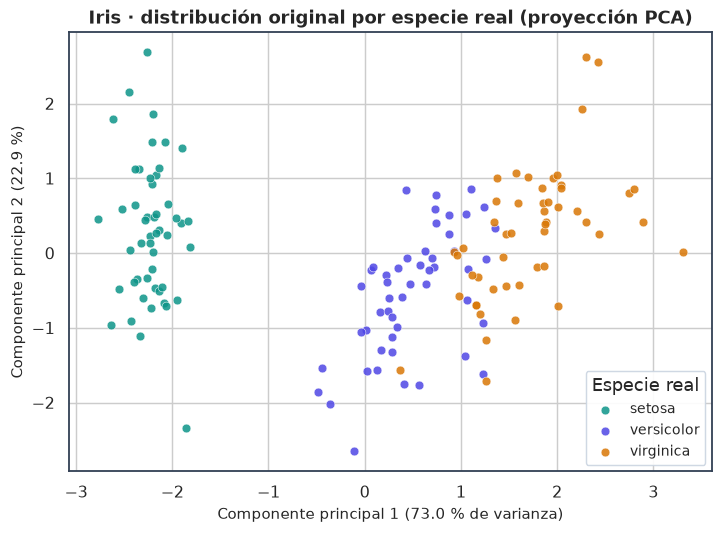

In [ ]:
# =====================================================================
# 05.2 · Distribución original de Iris (proyección PCA)
# =====================================================================
fig, eje = plt.subplots(figsize=(7.0, 5.2))
for i, especie in enumerate(especies):
    mascara = y_iris == i
    eje.scatter(X_iris_pca[mascara, 0], X_iris_pca[mascara, 1], s=36,
                c=PALETA_CLUSTER[i], alpha=0.85, edgecolors="white",
                linewidths=0.4, label=especie)
eje.set_xlabel(f"Componente principal 1 ({pca_iris.explained_variance_ratio_[0]*100:.1f} % de varianza)")
eje.set_ylabel(f"Componente principal 2 ({pca_iris.explained_variance_ratio_[1]*100:.1f} %)")
eje.set_title("Iris · distribución original por especie real (proyección PCA)")
eje.legend(title="Especie real")
fig.tight_layout()
print("Figura guardada en:", guardar_figura(fig, "iris_original_pca"))
plt.show()

### 05.3 · K-means: parámetros y método del codo

K-means minimiza la inercia (WCSS) asignando iterativamente cada punto al centroide más cercano y recalculando centroides como medias de los puntos asignados. Sus hiperparámetros principales:

| Parámetro | Rol | Valor usado |
|:--|:--|:--|
| `n_clusters` ($K$) | Número de particiones a construir; debe fijarse **antes** de entrenar | barrido 1–10; selección justificada abajo |
| `n_init` | Número de inicializaciones aleatorias de centroides; se conserva la de menor inercia. Mitiga mínimos locales | `10` |
| `random_state` | Semilla que hace reproducible la inicialización aleatoria | `42` |

El **método del codo** entrena K-means para $K = 1, \dots, 10$ y examina la inercia: se busca el punto donde la reducción marginal deja de ser sustancial. Se acompaña con la silueta por $K$ como criterio interno complementario.


Tabla del codo guardada en: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados/metricas/iris_codo_kmeans.csv


,K,Inercia,Silueta
0,1,600.000,NaN
1,2,222.362,0.582
2,3,139.820,0.460
3,4,114.093,0.387
4,5,90.928,0.346
5,6,81.544,0.317
6,7,72.631,0.320
7,8,62.541,0.339
8,9,55.119,0.342
9,10,47.391,0.352


Figura guardada en: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados/graficas/iris_elbow.png


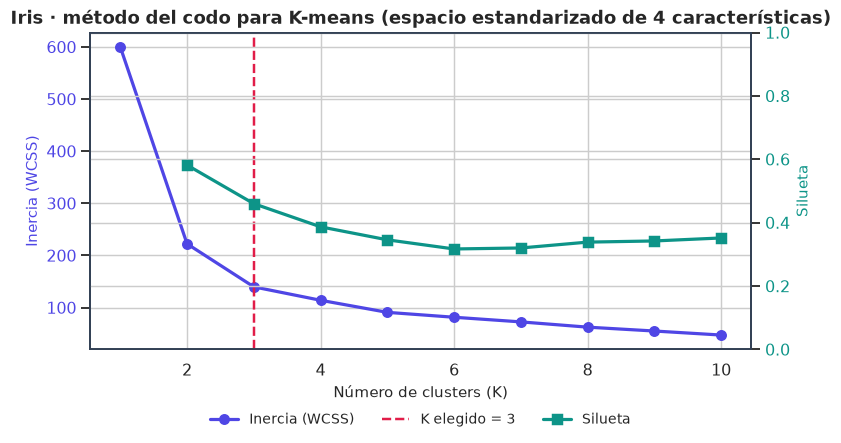

In [ ]:
# =====================================================================
# 05.4 · Método del codo sobre Iris (K = 1..10)
# =====================================================================
tabla_codo_iris = metodo_codo(X_iris_std, range(1, 11))
print("Tabla del codo guardada en:",
      guardar_tabla(tabla_codo_iris, "iris_codo_kmeans"))
display(tabla_codo_iris.round(3))
figura_codo(tabla_codo_iris, k_elegido=3,
            titulo="Iris · método del codo para K-means (espacio estandarizado de 4 características)",
            archivo="iris_elbow")

**Justificación de la selección de $K$.** La inercia cae fuertemente de $K=1$ a $K=2$ y de $K=2$ a $K=3$; a partir de $K=3$ las ganancias marginales se atenúan (comportamiento de "codo" en $K = 3$). La silueta, en cambio, alcanza su máximo en $K=2$: este desacuerdo es un resultado clásico de Iris y refleja que *versicolor* y *virginica* se solapan, de modo que una partición en 2 grupos (una especie frente a las otras dos fusionadas) es más "limpia" geométricamente.

**Decisión documentada:** se selecciona $K = 3$ porque (i) el codo de la inercia se ubica en 3, (ii) el diseño del dataset documenta tres especies botánicas y fragmentar o fusionar especies distintas no es deseable desde el punto de vista del problema, y (iii) $K=2$ fusionaría dos especies diferentes en un mismo cluster. Se deja constancia de que la silueta interna preferiría $K=2$: la elección prioriza el criterio del codo y el conocimiento documentado del problema, no las etiquetas reales como objetivo de optimización.


Figura guardada en: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados/graficas/iris_kmeans_pca.png


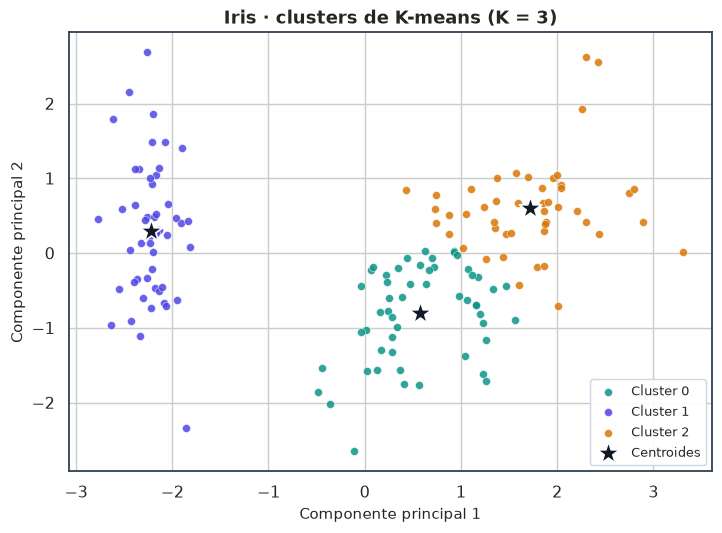

Dataset,Algoritmo,Clusters,Ruido,ARI,V-medida,Silueta,Davies-Bouldin
Iris,K-means,3,0,0.620,0.659,0.460,0.834


In [ ]:
# =====================================================================
# 05.5 · K-means final sobre Iris (K = 3)
# =====================================================================
kmeans_iris = KMeans(n_clusters=3, n_init=10, random_state=SEED)
etiquetas_kmeans_iris = kmeans_iris.fit_predict(X_iris_std)

# Proyección de los centroides al plano PCA (solo para graficar)
centroides_iris_pca = pca_iris.transform(kmeans_iris.cluster_centers_)

fig, eje = plt.subplots(figsize=(7.0, 5.2))
scatter_clusters(eje, X_iris_pca, etiquetas_kmeans_iris,
                 "Iris · clusters de K-means (K = 3)",
                 centroides=centroides_iris_pca)
eje.set_xlabel("Componente principal 1")
eje.set_ylabel("Componente principal 2")
fig.tight_layout()
print("Figura guardada en:", guardar_figura(fig, "iris_kmeans_pca"))
plt.show()

fila_kmeans_iris = registrar_resultado(
    "Iris", "K-means",
    "n_clusters=3, n_init=10, random_state=42",
    X_iris_std, etiquetas_kmeans_iris, y_iris)
display(mostrar_fila(fila_kmeans_iris))

### 05.6 · DBSCAN: parámetros y heurística de la k-distancia

DBSCAN agrupa puntos por **densidad**: un punto es *núcleo* si tiene al menos `min_samples` vecinos dentro de un radio `eps`; los clusters son conjuntos máximos de puntos núcleo conectados, y los puntos alcanzables pero no núcleos son *frontera*. Un punto que no cumple ninguna condición es **ruido** (etiqueta $-1$).

| Parámetro | Rol | Efecto |
|:--|:--|:--|
| `eps` | Radio de vecindad | Muy pequeño → muchos puntos quedan como ruido y el algoritmo sobre-segmenta; muy grande → los grupos se fusionan en uno o pocos clusters |
| `min_samples` | Umbral de densidad (n.º de vecinos) | Mayor exigencia → menos puntos núcleo, más ruido, clusters más "densos" |

Como `eps` y `min_samples` no pueden fijarse con etiquetas, se usa la **heurística estándar de la curva k-distancia**: para un `min_samples` dado se calcula, para cada punto, la distancia a su $k$-ésimo vecino más cercano, se ordena y se busca la **rodilla** de la curva; valores de `eps` en esa región separan puntos de densidad "normal" de los de baja densidad (ruido). En este experimento se usa `min_samples = 5` (valor de referencia para 150 muestras en 4 dimensiones) y se explora el entorno de la rodilla.


Figura guardada en: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados/graficas/iris_dbscan_kdist.png


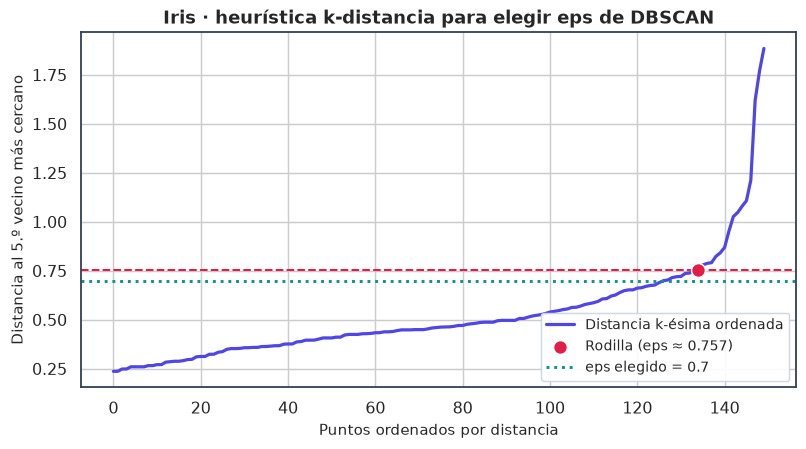

Valor de la rodilla detectada: eps ≈ 0.757


In [ ]:
# =====================================================================
# 05.7 · Curva k-distancia de Iris (min_samples = 5)
# =====================================================================
rodilla_iris = figura_kdistancia(
    X_iris_std, min_samples=5, eps_elegido=0.7,
    titulo="Iris · heurística k-distancia para elegir eps de DBSCAN",
    archivo="iris_dbscan_kdist")
print(f"Valor de la rodilla detectada: eps ≈ {rodilla_iris:.3f}")

In [ ]:
# =====================================================================
# 05.8 · Barrido de eps y min_samples para DBSCAN sobre Iris
# =====================================================================
tabla_dbscan_iris = barrido_dbscan(
    X_iris_std,
    valores_eps=[0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.2],
    valores_min_samples=[4, 5, 10])
print("Barrido guardado en:",
      guardar_tabla(tabla_dbscan_iris, "iris_dbscan_barrido"))
display(tabla_dbscan_iris.round(3))

Barrido guardado en: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados/metricas/iris_dbscan_barrido.csv


,eps,min_samples,Clusters,Ruido,Ruido (%),Silueta*,Davies-Bouldin*
0,0.4,4,5,61,40.667,0.502,0.777
1,0.4,5,6,66,44.000,0.486,0.786
2,0.4,10,2,118,78.667,0.523,0.688
3,0.5,4,2,33,22.000,0.655,0.495
4,0.5,5,2,34,22.667,0.656,0.494
5,0.5,10,3,89,59.333,0.710,0.374
6,0.6,4,3,19,12.667,0.547,0.525
7,0.6,5,2,26,17.333,0.642,0.512
8,0.6,10,2,35,23.333,0.650,0.504
9,0.7,4,2,5,3.333,0.600,0.566


**Lectura del barrido.** Con `eps` pequeño (0.4–0.5) el algoritmo sobre-segmenta (3 clusters) y marca decenas de puntos como ruido, porque la vecindad exigida es menor que la densidad real de los grupos. Al acercarse a la rodilla de la k-distancia (≈ 0.7–0.8) la partición se **estabiliza en 2 clusters con ruido mínimo** (4–8 puntos), y con `eps` grande (≥ 1.2) prácticamente desaparece el ruido pero los dos grupos persisten. Un `eps` todavía mayor terminaría fusionando todo en un único cluster.

**Decisión documentada:** `eps = 0.7`, `min_samples = 5`. El valor está en la región de la rodilla detectada (≈ 0.76), produce una partición estable (2 clusters, ≤ 4 % de ruido) y no recurre a las etiquetas reales. Es representativo que DBSCAN encuentre **2** grupos densos y no 3: en el espacio estandarizado, *versicolor* y *virginica* forman una única región de densidad conectada, y DBSCAN solo puede separarlas si se reduce `eps` a costa de generar ruido artificial (sobre-segmentación visible en el barrido con `eps = 0.5`).


Conteo de puntos por etiqueta (-1 = ruido):
-1     6
 0    48
 1    96


Figura guardada en: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados/graficas/iris_dbscan_pca.png


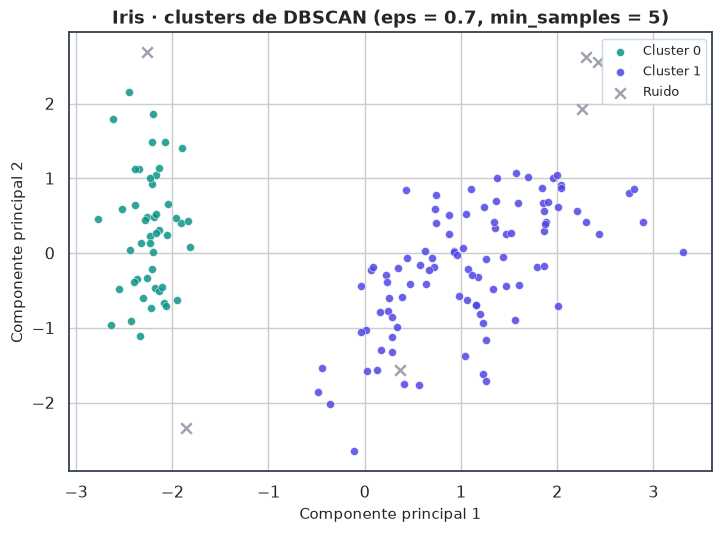

Dataset,Algoritmo,Clusters,Ruido,ARI,V-medida,Silueta,Davies-Bouldin
Iris,DBSCAN,2,6,0.540,0.671,0.602,0.557


Nota sobre métricas internas: Calculadas excluyendo los puntos de ruido de DBSCAN.


In [ ]:
# =====================================================================
# 05.9 · DBSCAN final sobre Iris (eps = 0.7, min_samples = 5)
# =====================================================================
dbscan_iris = DBSCAN(eps=0.7, min_samples=5)
etiquetas_dbscan_iris = dbscan_iris.fit_predict(X_iris_std)

print("Conteo de puntos por etiqueta (-1 = ruido):")
print(pd.Series(etiquetas_dbscan_iris).value_counts().sort_index().to_string())

fig, eje = plt.subplots(figsize=(7.0, 5.2))
scatter_clusters(eje, X_iris_pca, etiquetas_dbscan_iris,
                 "Iris · clusters de DBSCAN (eps = 0.7, min_samples = 5)")
eje.set_xlabel("Componente principal 1")
eje.set_ylabel("Componente principal 2")
fig.tight_layout()
print("Figura guardada en:", guardar_figura(fig, "iris_dbscan_pca"))
plt.show()

fila_dbscan_iris = registrar_resultado(
    "Iris", "DBSCAN", "eps=0.7, min_samples=5",
    X_iris_std, etiquetas_dbscan_iris, y_iris)
display(mostrar_fila(fila_dbscan_iris))
print("Nota sobre métricas internas:",
      evaluar_internas(X_iris_std, etiquetas_dbscan_iris)["Nota"])

### 05.10 · SpectralClustering: afinidad, gamma y la matriz de similitud

SpectralClustering construye una **matriz de similitud** $W$ entre pares de puntos, la interpreta como un grafo ponderado y particiona el grafo usando su **espectro** (autovectores del Laplaciano $L = D - W$): los puntos se proyectan sobre los primeros $k$ autovectores y en ese espacio embebido se aplica K-means. La matriz de similitud es **el corazón del método**: define qué significa "estar conectado" y, por tanto, qué estructuras pueden descubrirse.

| Parámetro | Rol |
|:--|:--|
| `n_clusters` ($k$) | Número de particiones; determina cuántos autovectores del Laplaciano se usan |
| `affinity` | Construcción de $W$: `'rbf'` (kernel gaussiano sobre todas las parejas) o `'nearest_neighbors'` (grafo de $k$ vecinos) |
| `gamma` (solo `affinity='rbf'`) | Ancho de banda del kernel: $w_{ij} = \exp(-\gamma \|x_i - x_j\|^2)$ |

**Efecto de `gamma` con afinidad RBF:** valores pequeños producen un kernel ancho (grafo denso, todo se parece a todo y la estructura se difumina); valores grandes producen un kernel estrecho (solo los vecinos inmediados tienen similitud apreciable, el grafo se vuelve disperso y puede desconectarse). El barrido explora $\gamma \in \{0.25, 0.5, 1, 2, 5\}$ con $k=3$, la alternativa `nearest_neighbors` con 5, 10 y 15 vecinos, y $k \in \{2, 4\}$ para verificar la sensibilidad a $k$. Se registra además si el grafo quedó totalmente conectado: un grafo desconectado indica que la afinidad es demasiado local.


In [ ]:
# =====================================================================
# 05.11 · Barrido de configuraciones de SpectralClustering sobre Iris
# =====================================================================
configuraciones_spectral_iris = (
    [{"n_clusters": 3, "affinity": "rbf", "gamma": g}
     for g in (0.25, 0.5, 1.0, 2.0, 5.0)]
    + [{"n_clusters": 3, "affinity": "nearest_neighbors", "n_neighbors": n}
       for n in (5, 10, 15)]
    + [{"n_clusters": k, "affinity": "nearest_neighbors", "n_neighbors": 10}
       for k in (2, 4)]
)
tabla_spectral_iris = barrido_spectral(X_iris_std, configuraciones_spectral_iris)
print("Barrido guardado en:",
      guardar_tabla(tabla_spectral_iris, "iris_spectral_barrido"))
display(tabla_spectral_iris.round(3))

Barrido guardado en: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados/metricas/iris_spectral_barrido.csv


,Configuración,Grafo conexo,Clusters,Ruido,Silueta,Davies-Bouldin
0,"n_clusters=3, affinity=rbf, gamma=0.25",Sí,3,0,0.460,0.831
1,"n_clusters=3, affinity=rbf, gamma=0.5",Sí,3,0,0.460,0.831
2,"n_clusters=3, affinity=rbf, gamma=1.0",Sí,3,0,0.463,0.826
3,"n_clusters=3, affinity=rbf, gamma=2.0",Sí,3,0,0.495,0.534
4,"n_clusters=3, affinity=rbf, gamma=5.0",Sí,3,0,0.495,0.534
5,"n_clusters=3, affinity=nearest_neighbors, n_ne...",No,3,0,0.495,0.653
6,"n_clusters=3, affinity=nearest_neighbors, n_ne...",Sí,3,0,0.459,0.822
7,"n_clusters=3, affinity=nearest_neighbors, n_ne...",Sí,3,0,0.463,0.832
8,"n_clusters=2, affinity=nearest_neighbors, n_ne...",Sí,2,0,0.582,0.593
9,"n_clusters=4, affinity=nearest_neighbors, n_ne...",Sí,4,0,0.389,0.837


**Lectura del barrido.** Con afinidad RBF y $k = 3$, la silueta mejora al aumentar $\gamma$ de 0.25 a 2.0 y se satura hacia $\gamma = 5$: valores intermedios (2.0) capturan la estructura local sin hacer el grafo excesivamente disperso. La afinidad por $k$ vecinos produce particiones comparables, pero en Iris puede dejar el **grafo desconectado**: la nube de *setosa* está tan separada del resto que un número reducido de vecinos no alcanza a conectar ambos bloques — sklearn lo advierte y SpectralClustering aún así produce $k$ particiones porque el paso final es K-means sobre el embedding.

**Decisión documentada:** `n_clusters = 3`, `affinity = 'rbf'`, `gamma = 2.0`. Es la configuración con mejor silueta interna entre las RBF sin llegar a la zona de saturación ($\gamma = 5$), y mantiene el grafo conectado.


Figura guardada en: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados/graficas/iris_spectral_pca.png


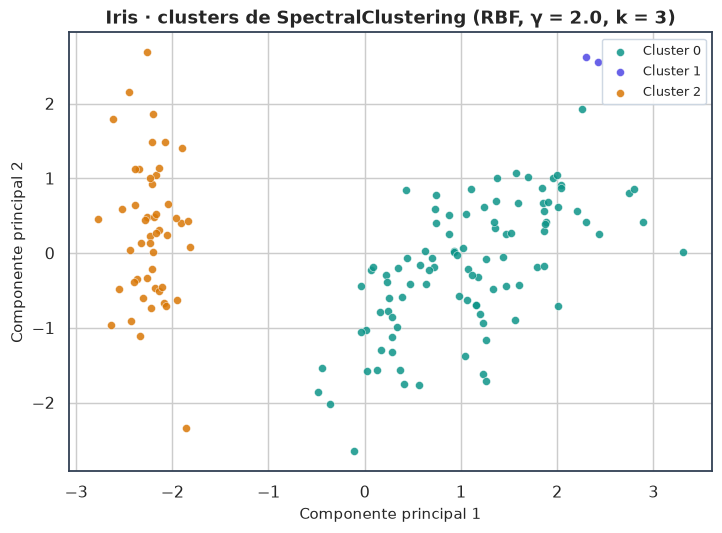

Dataset,Algoritmo,Clusters,Ruido,ARI,V-medida,Silueta,Davies-Bouldin
Iris,Spectral,3,0,0.564,0.717,0.495,0.534


In [ ]:
# =====================================================================
# 05.12 · SpectralClustering final sobre Iris (rbf, gamma = 2.0, k = 3)
# =====================================================================
spectral_iris = SpectralClustering(n_clusters=3, affinity="rbf", gamma=2.0,
                                    random_state=SEED, n_init=10)
etiquetas_spectral_iris = spectral_iris.fit_predict(X_iris_std)

fig, eje = plt.subplots(figsize=(7.0, 5.2))
scatter_clusters(eje, X_iris_pca, etiquetas_spectral_iris,
                 "Iris · clusters de SpectralClustering (RBF, γ = 2.0, k = 3)")
eje.set_xlabel("Componente principal 1")
eje.set_ylabel("Componente principal 2")
fig.tight_layout()
print("Figura guardada en:", guardar_figura(fig, "iris_spectral_pca"))
plt.show()

fila_spectral_iris = registrar_resultado(
    "Iris", "Spectral", "n_clusters=3, affinity=rbf, gamma=2.0",
    X_iris_std, etiquetas_spectral_iris, y_iris)
display(mostrar_fila(fila_spectral_iris))

Figura guardada en: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados/graficas/iris_similitud_rbf.png


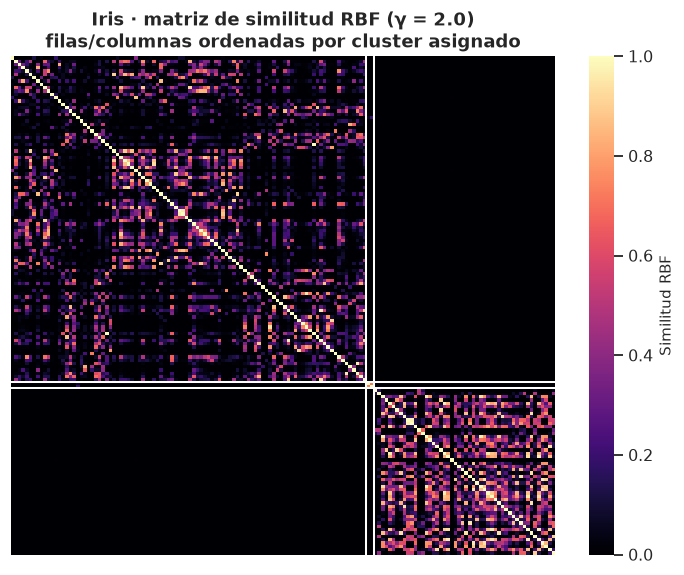

Los bloques claros de la diagonal son pares con similitud alta dentro de un mismo cluster;
las zonas oscuras corresponden a pares de clusters distintos (similitud cercana a 0).


In [ ]:
# =====================================================================
# 05.13 · Matriz de similitud RBF de Iris (gamma = 2.0)
# =====================================================================
# w_ij = exp(-gamma * ||x_i - x_j||^2): la matriz que SpectralClustering
# "lee" antes de calcular el Laplaciano y su espectro.
S_iris = rbf_kernel(X_iris_std, gamma=2.0)
orden = np.argsort(etiquetas_spectral_iris)

fig, eje = plt.subplots(figsize=(6.8, 5.6))
sns.heatmap(S_iris[np.ix_(orden, orden)], ax=eje, cmap="magma",
            cbar_kws={"label": "Similitud RBF"}, xticklabels=False,
            yticklabels=False, vmin=0, vmax=1)
fronteras = np.cumsum(np.bincount(etiquetas_spectral_iris[orden]))
for limite in fronteras[:-1]:
    eje.axhline(limite, color="white", lw=1.4)
    eje.axvline(limite, color="white", lw=1.4)
eje.set_title("Iris · matriz de similitud RBF (γ = 2.0)\nfilas/columnas ordenadas por cluster asignado")
fig.tight_layout()
print("Figura guardada en:", guardar_figura(fig, "iris_similitud_rbf"))
plt.show()
print("Los bloques claros de la diagonal son pares con similitud alta dentro de un mismo cluster;")
print("las zonas oscuras corresponden a pares de clusters distintos (similitud cercana a 0).")

Figura guardada en: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados/graficas/iris_comparacion.png


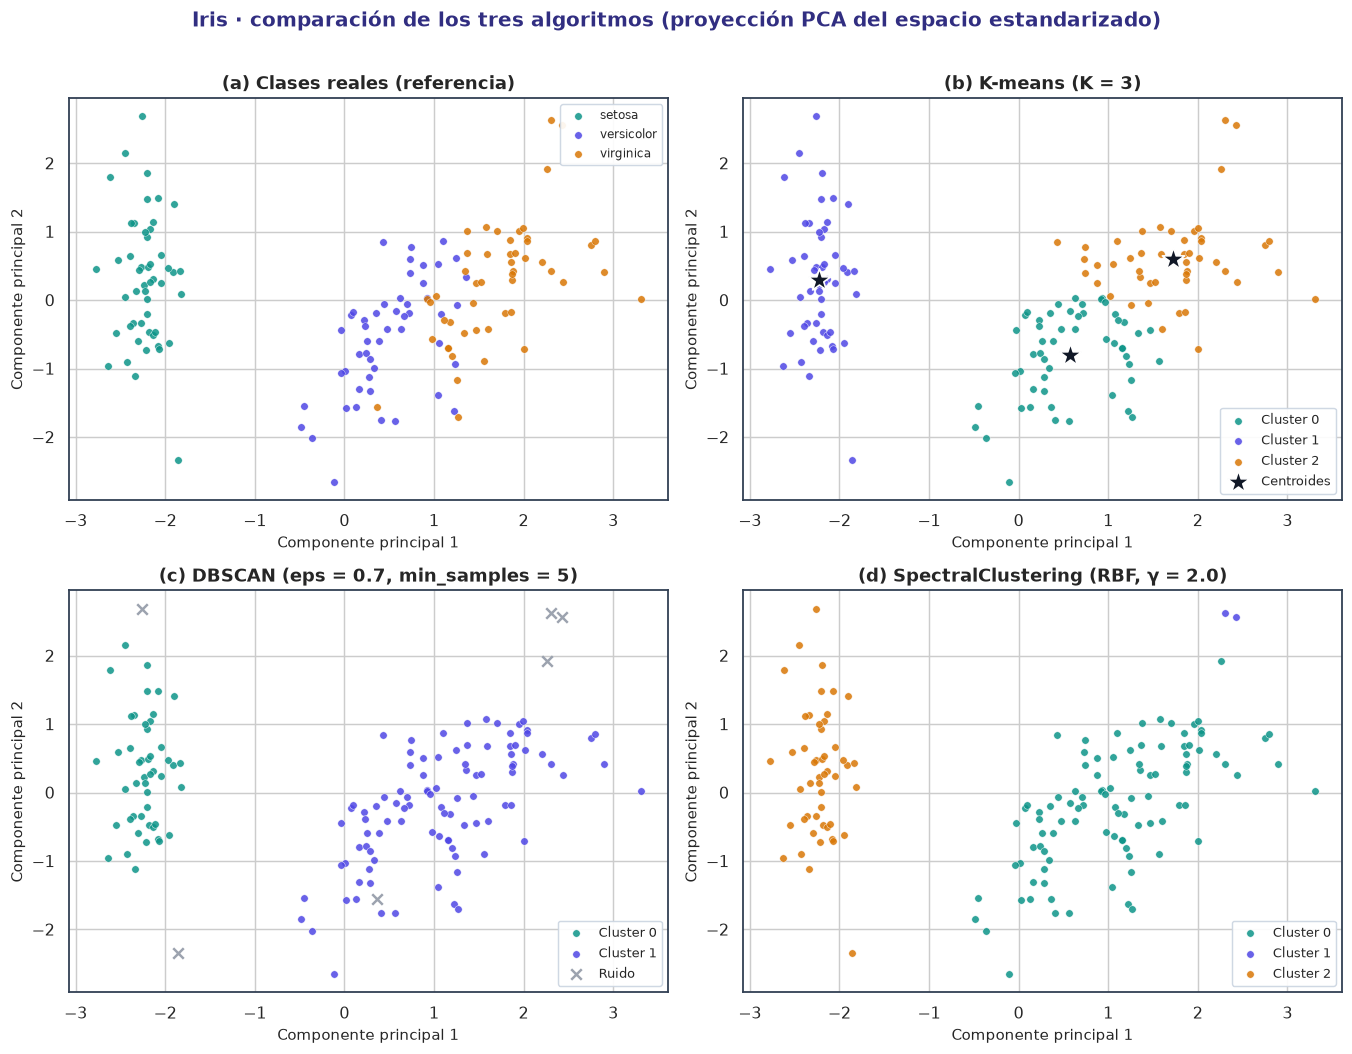

Tabla de resultados guardada en: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados/metricas/iris_resultados.csv


,Dataset,Algoritmo,Clusters,Ruido,ARI,V-medida,Silueta,Davies-Bouldin
0,Iris,K-means,3,0,0.620,0.659,0.460,0.834
1,Iris,DBSCAN,2,6,0.540,0.671,0.602,0.557
2,Iris,Spectral,3,0,0.564,0.717,0.495,0.534


Figura guardada en: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados/graficas/iris_metricas.png


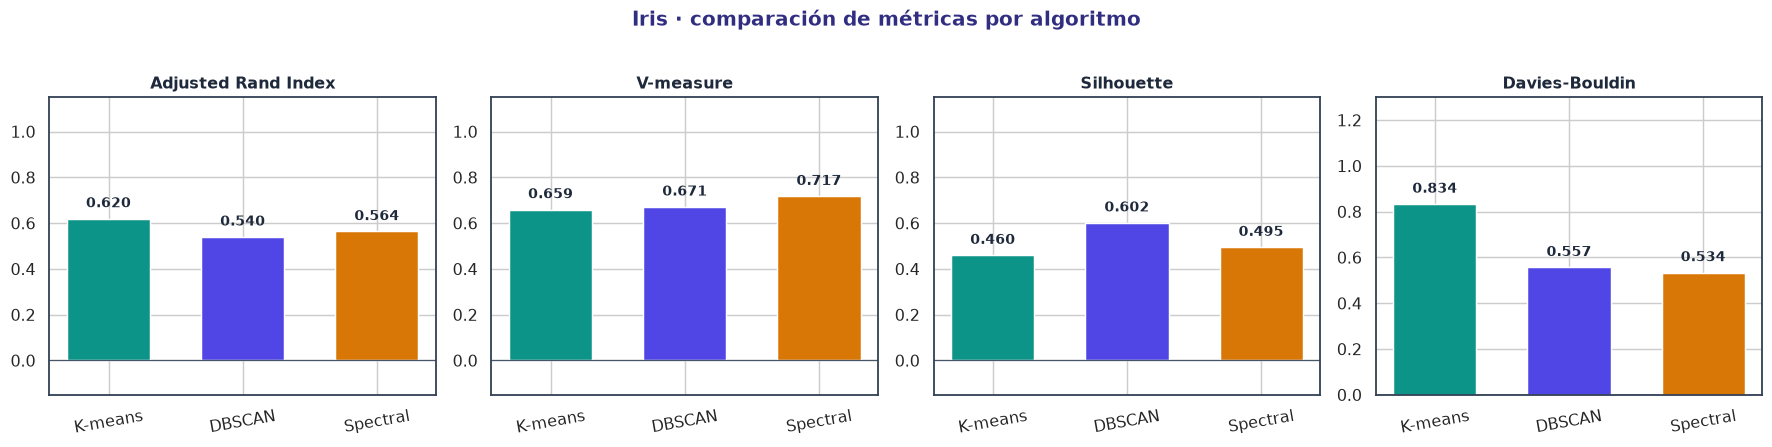

In [ ]:
# =====================================================================
# 05.14 · Comparación visual y de métricas sobre Iris
# =====================================================================
fig, ejes = plt.subplots(2, 2, figsize=(13.0, 10.2))

eje = ejes[0, 0]
for i, especie in enumerate(especies):
    mascara = y_iris == i
    eje.scatter(X_iris_pca[mascara, 0], X_iris_pca[mascara, 1], s=26,
                c=PALETA_CLUSTER[i], alpha=0.85, edgecolors="white",
                linewidths=0.3, label=especie)
eje.set_title("(a) Clases reales (referencia)")
eje.legend(fontsize=8.5, loc="upper right")

eje = ejes[0, 1]
scatter_clusters(eje, X_iris_pca, etiquetas_kmeans_iris,
                 "(b) K-means (K = 3)", tamanos=26,
                 centroides=centroides_iris_pca)

eje = ejes[1, 0]
scatter_clusters(eje, X_iris_pca, etiquetas_dbscan_iris,
                 "(c) DBSCAN (eps = 0.7, min_samples = 5)", tamanos=26)

eje = ejes[1, 1]
scatter_clusters(eje, X_iris_pca, etiquetas_spectral_iris,
                 "(d) SpectralClustering (RBF, γ = 2.0)", tamanos=26)

for eje in ejes.flat:
    eje.set_xlabel("Componente principal 1")
    eje.set_ylabel("Componente principal 2")
fig.suptitle("Iris · comparación de los tres algoritmos (proyección PCA del espacio estandarizado)",
             fontsize=14, fontweight="bold", color=INDIGO_OSCURO)
fig.tight_layout(rect=(0, 0, 1, 0.97))
print("Figura guardada en:", guardar_figura(fig, "iris_comparacion"))
plt.show()

# Tabla y figura de métricas del dataset Iris
tabla_resultados_iris = pd.DataFrame([f for f in RESULTADOS if f["Dataset"] == "Iris"])
print("Tabla de resultados guardada en:",
      guardar_tabla(tabla_resultados_iris, "iris_resultados"))
display(tabla_resultados_iris.drop(columns=["Hiperparámetros"]).round(3))
figura_comparacion_metricas(tabla_resultados_iris,
                            "Iris · comparación de métricas por algoritmo",
                            "iris_metricas")

### 05.15 · Interpretación de los resultados de Iris

**Lectura de las métricas externas.** Los tres algoritmos obtienen ARI y V-measure positivos y claramente superiores al azar, coherentes con la estructura del dataset: *setosa* es el grupo fácil (K-means y SpectralClustering la aíslan en un cluster puro de 50 muestras; DBSCAN agrupa 48 de sus 50 puntos y marca los 2 restantes como ruido), mientras que la recuperación de las etiquetas queda limitada por el **solapamiento real** entre *versicolor* y *virginica*. K-means obtiene el mayor ARI (0.620) al fijar $k=3$ y cortar ese solapamiento; DBSCAN obtiene un ARI algo menor (0.540) porque descubre solo **2** regiones de densidad (*setosa* frente al bloque *versicolor+virginica* fusionado); SpectralClustering queda intermedio (0.564) y logra la mayor V-measure del dataset (0.717). La V-measure descompone estos comportamientos mediante la homogeneidad ($h$) y la completitud ($c$): la partición de DBSCAN es **completa** ($c \approx 0.81$: cada especie queda concentrada en un único cluster) pero poco **homogénea** ($h \approx 0.57$: un mismo cluster contiene dos especies); SpectralClustering logra $c \approx 0.92$ a costa de $h \approx 0.59$; y K-means queda equilibrado ($h \approx c \approx 0.66$) al trocear ambas especies solapadas.

**Lectura de las métricas internas.** La silueta de K-means con $K=3$ (0.460) es la más baja de las tres configuraciones: el corte entre *versicolor* y *virginica* atraviesa una zona de solapamiento real. DBSCAN alcanza la silueta más alta (0.602) porque su partición de 2 grupos ni siquiera intenta separar ese solapamiento; SpectralClustering queda intermedio (0.495) porque, aunque fija $k=3$, su corte de la zona difícil difiere del de K-means. El índice Davies-Bouldin (menor es mejor) ordena igual: Spectral 0.534 < DBSCAN 0.557 < K-means 0.834. En Iris las métricas externas e internas **coinciden cualitativamente** en señalar la dificultad del par *versicolor/virginica*, a diferencia de lo que ocurrirá en Moons y Circles, donde la silueta premia particiones geométricamente incorrectas.

**Sobre el ruido de DBSCAN:** los 6 puntos marcados como ruido son 2 *setosa* aisladas y 4 puntos de la zona de solapamiento *versicolor/virginica*: puntos de baja densidad relativa que DBSCAN prefiere no comprometer con ningún cluster, lo cual es información útil (detección de anomalías) y no un defecto del ajuste.


---
## 06 · Experimento 2 — Dataset Moons
---

El dataset sintético **Moons** se genera con `make_moons` y contiene dos estructuras con forma de media luna **entrelazadas**. Es el experimento crítico para contrastar modelos convexos frente a modelos de densidad/espectrales: las dos lunas son **no convexas** y **anidadas**, de modo que ninguna frontera lineal razonable puede separarlas, y la partición "natural" sigue la curvatura de cada luna.

**Configuración de generación (reproducible):** `make_moons(n_samples=500, noise=0.1, random_state=42)`. Las etiquetas devueltas por el generador (luna 1 / luna 2) se usan **únicamente** como referencia para la validación externa. Las dos características están en escalas comparables (aprox. $[-1.5, 1.5]$), por lo que los modelos se entrenan sobre las coordenadas originales **sin reescalar** (decisión documentada: ninguna característica domina la distancia euclidiana).


Forma de X_moons: (500, 2)
Puntos por estructura: [250 250]


Figura guardada en: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados/graficas/moons_original.png


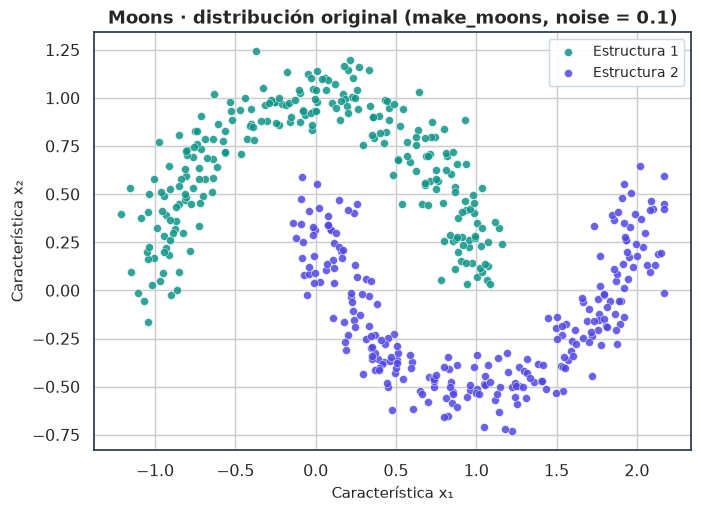

In [ ]:
# =====================================================================
# 06.1 · Generación de Moons y distribución original
# =====================================================================
X_moons, y_moons = make_moons(n_samples=500, noise=0.1, random_state=SEED)
print("Forma de X_moons:", X_moons.shape)
print("Puntos por estructura:", np.bincount(y_moons))

fig, eje = plt.subplots(figsize=(6.8, 5.0))
for etiqueta, color, nombre in ((0, PALETA_CLUSTER[0], "Estructura 1"),
                                (1, PALETA_CLUSTER[1], "Estructura 2")):
    mascara = y_moons == etiqueta
    eje.scatter(X_moons[mascara, 0], X_moons[mascara, 1], s=30, c=color,
                alpha=0.85, edgecolors="white", linewidths=0.35, label=nombre)
eje.set_xlabel("Característica x₁")
eje.set_ylabel("Característica x₂")
eje.set_title("Moons · distribución original (make_moons, noise = 0.1)")
eje.legend()
fig.tight_layout()
print("Figura guardada en:", guardar_figura(fig, "moons_original"))
plt.show()

Tabla del codo guardada en: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados/metricas/moons_codo_kmeans.csv


,K,Inercia,Silueta
0,1,511.393,NaN
1,2,209.570,0.483
2,3,140.686,0.420
3,4,91.690,0.449
4,5,68.710,0.476
5,6,48.290,0.512
6,7,38.624,0.511
7,8,31.713,0.510


Figura guardada en: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados/graficas/moons_elbow.png


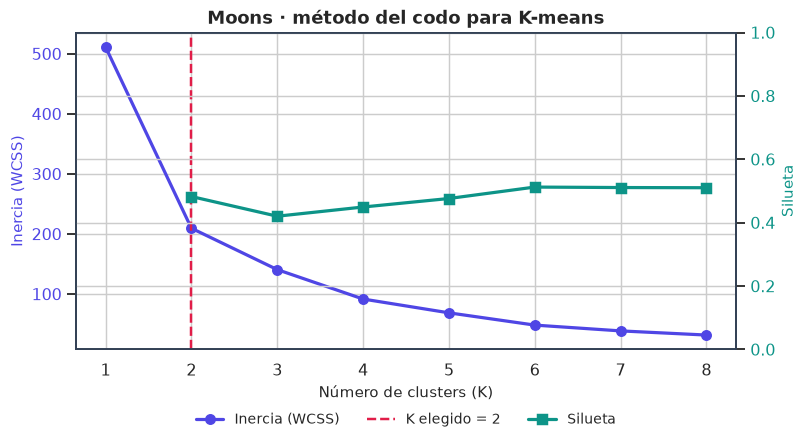

In [ ]:
# =====================================================================
# 06.2 · Método del codo para K-means sobre Moons
# =====================================================================
tabla_codo_moons = metodo_codo(X_moons, range(1, 9))
print("Tabla del codo guardada en:",
      guardar_tabla(tabla_codo_moons, "moons_codo_kmeans"))
display(tabla_codo_moons.round(3))
figura_codo(tabla_codo_moons, k_elegido=2,
            titulo="Moons · método del codo para K-means",
            archivo="moons_elbow")

**Selección de $K$ en Moons.** La caída de inercia de $K=1$ a $K=2$ es la más pronunciada (511 → 210) y a partir de $K=2$ la curva se aplana: el codo indica **$K = 2$**, lo que además coincide con el diseño del generador (dos estructuras entrelazadas). Obsérvese que la silueta **crece** con $K$ en este dataset (hasta 0.512 con $K=6$): partir las lunas en más trozos produce grupos más compactos y la silueta los premia — otra manifestación del sesgo convexo de las métricas internas. Se entrena K-means con $K=2$, `n_init=10` y `random_state=42`.


Figura guardada en: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados/graficas/moons_kmeans.png


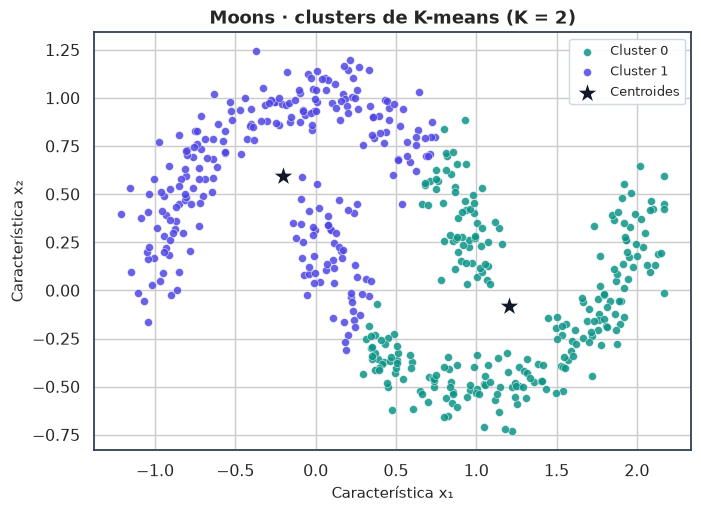

Dataset,Algoritmo,Clusters,Ruido,ARI,V-medida,Silueta,Davies-Bouldin
Moons,K-means,2,0,0.265,0.202,0.483,0.789


In [ ]:
# =====================================================================
# 06.3 · K-means sobre Moons (K = 2)
# =====================================================================
kmeans_moons = KMeans(n_clusters=2, n_init=10, random_state=SEED)
etiquetas_kmeans_moons = kmeans_moons.fit_predict(X_moons)

fig, eje = plt.subplots(figsize=(6.8, 5.0))
scatter_clusters(eje, X_moons, etiquetas_kmeans_moons,
                 "Moons · clusters de K-means (K = 2)",
                 centroides=kmeans_moons.cluster_centers_)
eje.set_xlabel("Característica x₁")
eje.set_ylabel("Característica x₂")
fig.tight_layout()
print("Figura guardada en:", guardar_figura(fig, "moons_kmeans"))
plt.show()

fila_kmeans_moons = registrar_resultado(
    "Moons", "K-means", "n_clusters=2, n_init=10, random_state=42",
    X_moons, etiquetas_kmeans_moons, y_moons)
display(mostrar_fila(fila_kmeans_moons))

Figura guardada en: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados/graficas/moons_dbscan_kdist.png


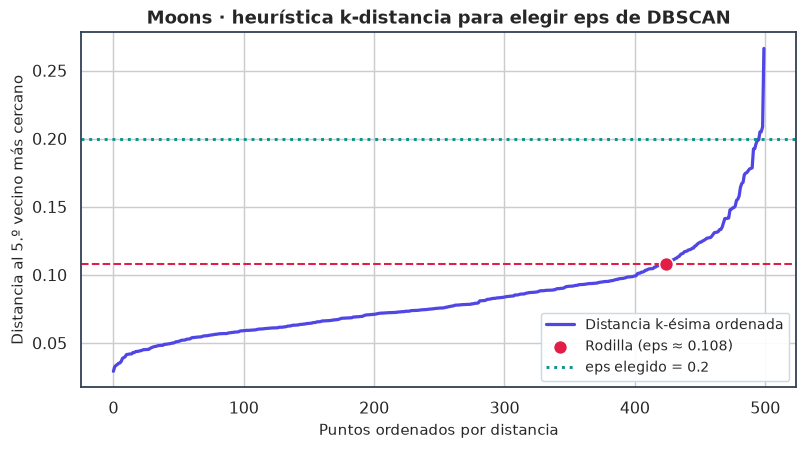

Valor de la rodilla detectada: eps ≈ 0.108
Barrido guardado en: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados/metricas/moons_dbscan_barrido.csv


,eps,min_samples,Clusters,Ruido,Ruido (%),Silueta*,Davies-Bouldin*
0,0.08,5,19,91,18.2,0.244,0.796
1,0.08,10,3,456,91.2,0.880,0.162
2,0.10,5,6,37,7.4,0.199,1.080
3,0.10,10,16,202,40.4,0.519,0.592
4,0.12,5,2,20,4.0,0.329,1.155
5,0.12,10,7,51,10.2,0.476,0.615
6,0.15,5,2,2,0.4,0.326,1.161
7,0.15,10,2,14,2.8,0.330,1.151
8,0.18,5,2,1,0.2,0.327,1.159
9,0.18,10,2,3,0.6,0.330,1.151


In [ ]:
# =====================================================================
# 06.4 · Heurística k-distancia y barrido de DBSCAN sobre Moons
# =====================================================================
rodilla_moons = figura_kdistancia(
    X_moons, min_samples=5, eps_elegido=0.2,
    titulo="Moons · heurística k-distancia para elegir eps de DBSCAN",
    archivo="moons_dbscan_kdist")
print(f"Valor de la rodilla detectada: eps ≈ {rodilla_moons:.3f}")

tabla_dbscan_moons = barrido_dbscan(
    X_moons,
    valores_eps=[0.08, 0.10, 0.12, 0.15, 0.18, 0.20, 0.25, 0.30],
    valores_min_samples=[5, 10])
print("Barrido guardado en:",
      guardar_tabla(tabla_dbscan_moons, "moons_dbscan_barrido"))
display(tabla_dbscan_moons.round(3))

**Lectura del barrido de DBSCAN en Moons.** La rodilla de la k-distancia está en `eps ≈ 0.11`. Con `eps` en torno a esa rodilla el algoritmo ya detecta 2 clusters, pero aún marca del orden de 20 puntos como ruido: el ruido gaussiano del generador deja zonas de menor densidad dentro de cada luna. A medida que `eps` crece hacia 0.15–0.20 el ruido desaparece **sin fusionar las dos lunas**; con `eps = 0.30` la vecindad alcanza a cruzar el hueco entre las lunas y todo colapsa en **un único cluster** (la silueta queda sin definir: se registra `NaN`, no un cero).

**Decisión documentada:** `eps = 0.2`, `min_samples = 5`. Es un valor de la región estable que elimina el ruido (2 clusters, 0 puntos de ruido) manteniendo margen de seguridad frente a la fusión que se observa en `eps = 0.25–0.30`. La elección se basa en la curva k-distancia y en la estabilidad de la partición (criterios internos y de comportamiento del algoritmo), no en las etiquetas.


Conteo de puntos por etiqueta (-1 = ruido):


0    250
1    250


Figura guardada en: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados/graficas/moons_dbscan.png


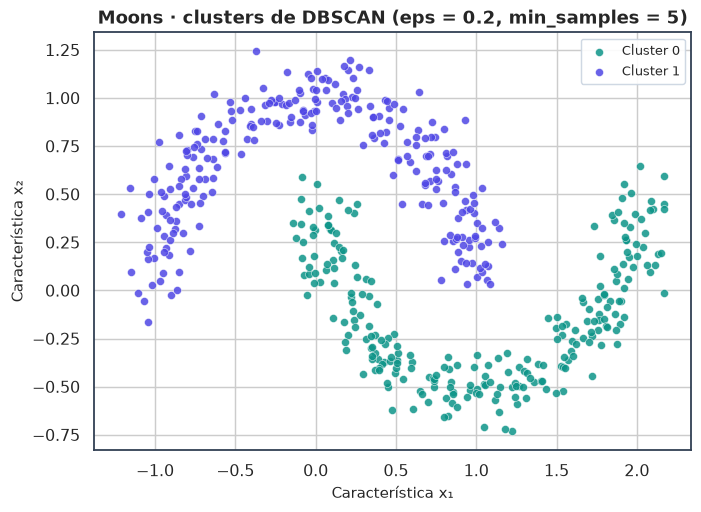

Dataset,Algoritmo,Clusters,Ruido,ARI,V-medida,Silueta,Davies-Bouldin
Moons,DBSCAN,2,0,1.000,1.000,0.327,1.156


In [ ]:
# =====================================================================
# 06.5 · DBSCAN final sobre Moons (eps = 0.2, min_samples = 5)
# =====================================================================
dbscan_moons = DBSCAN(eps=0.2, min_samples=5)
etiquetas_dbscan_moons = dbscan_moons.fit_predict(X_moons)

print("Conteo de puntos por etiqueta (-1 = ruido):")
print(pd.Series(etiquetas_dbscan_moons).value_counts().sort_index().to_string())

fig, eje = plt.subplots(figsize=(6.8, 5.0))
scatter_clusters(eje, X_moons, etiquetas_dbscan_moons,
                 "Moons · clusters de DBSCAN (eps = 0.2, min_samples = 5)")
eje.set_xlabel("Característica x₁")
eje.set_ylabel("Característica x₂")
fig.tight_layout()
print("Figura guardada en:", guardar_figura(fig, "moons_dbscan"))
plt.show()

fila_dbscan_moons = registrar_resultado(
    "Moons", "DBSCAN", "eps=0.2, min_samples=5",
    X_moons, etiquetas_dbscan_moons, y_moons)
display(mostrar_fila(fila_dbscan_moons))

### 06.6 · SpectralClustering sobre Moons: afinidad de vecinos contra RBF

En estructuras curvas, la afinidad adecuada codifica **conectividad local**: el grafo de $k$ vecinos más cercanos (`affinity='nearest_neighbors'`) conecta cada punto con sus vecinos inmediatos y las lunas se convierten en dos componentes casi conexas del grafo. La afinidad RBF, en cambio, pondera **todas** las parejas con $w_{ij} = \exp(-\gamma\|x_i-x_j\|^2)$: con $\gamma$ pequeño el kernel es tan ancho que ambas lunas quedan entrelazadas en el grafo (la partición decae hacia cortes tipo K-means); con $\gamma$ muy grande el grafo se vuelve tan local que puede fragmentarse.

El barrido explora $\gamma \in \{1, 5, 10, 30, 100\}$ y vecinos $\in \{5, 10, 15\}$ con $k = 2$.


In [ ]:
# =====================================================================
# 06.7 · Barrido de SpectralClustering sobre Moons
# =====================================================================
configuraciones_spectral_moons = (
    [{"n_clusters": 2, "affinity": "rbf", "gamma": g}
     for g in (1.0, 5.0, 10.0, 30.0, 100.0)]
    + [{"n_clusters": 2, "affinity": "nearest_neighbors", "n_neighbors": n}
       for n in (5, 10, 15)]
)
tabla_spectral_moons = barrido_spectral(X_moons, configuraciones_spectral_moons)
print("Barrido guardado en:",
      guardar_tabla(tabla_spectral_moons, "moons_spectral_barrido"))
display(tabla_spectral_moons.round(3))

Barrido guardado en: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados/metricas/moons_spectral_barrido.csv


,Configuración,Grafo conexo,Clusters,Ruido,Silueta,Davies-Bouldin
0,"n_clusters=2, affinity=rbf, gamma=1.0",Sí,2,0,0.484,0.789
1,"n_clusters=2, affinity=rbf, gamma=5.0",Sí,2,0,0.476,0.809
2,"n_clusters=2, affinity=rbf, gamma=10.0",Sí,2,0,0.412,0.923
3,"n_clusters=2, affinity=rbf, gamma=30.0",Sí,2,0,0.327,1.156
4,"n_clusters=2, affinity=rbf, gamma=100.0",Sí,2,0,0.327,1.156
5,"n_clusters=2, affinity=nearest_neighbors, n_ne...",No,2,0,0.327,1.156
6,"n_clusters=2, affinity=nearest_neighbors, n_ne...",Sí,2,0,0.327,1.156
7,"n_clusters=2, affinity=nearest_neighbors, n_ne...",Sí,2,0,0.327,1.156


**Decisión documentada.** Se selecciona `affinity='nearest_neighbors'` con `n_neighbors=10` y `k=2`: (i) es la afinidad que codifica la conectividad de la variedad subyacente (cada luna es una "cadena" de vecinos), (ii) es **robusta**: produce la misma partición correcta para 5, 10 y 15 vecinos, sin necesidad de calibrar un ancho de banda, y (iii) su comportamiento es transparente: con 5 vecinos el grafo k-NN queda exactamente en dos componentes (las dos lunas, la estructura ideal para el corte espectral) y con 10–15 vecinos el grafo se conecta pero el corte sigue siendo el correcto. El barrido RBF muestra que la silueta **disminuye** al aumentar $\gamma$ — no porque las particiones sean peores, sino porque la silueta favorece blobs convexos: con $\gamma$ pequeño, SpectralClustering corta las lunas "por la mitad" en dos mitades compactas (partición más parecida a la de K-means) y eso **sube** la silueta aunque la estructura sea incorrecta. Este comportamiento es una demostración experimental del sesgo de las métricas internas en datos no convexos y justifica no usarlas como único criterio de selección.


Figura guardada en: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados/graficas/moons_spectral.png


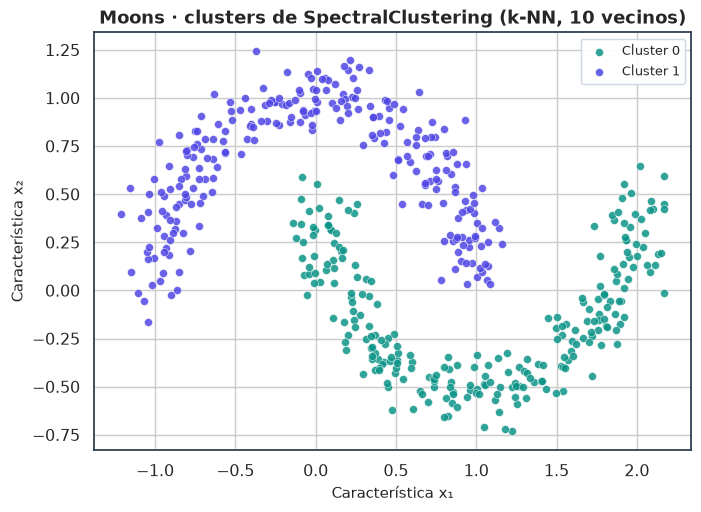

Dataset,Algoritmo,Clusters,Ruido,ARI,V-medida,Silueta,Davies-Bouldin
Moons,Spectral,2,0,1.000,1.000,0.327,1.156


In [ ]:
# =====================================================================
# 06.8 · SpectralClustering final sobre Moons (k-NN, 10 vecinos)
# =====================================================================
spectral_moons = SpectralClustering(n_clusters=2, affinity="nearest_neighbors",
                                    n_neighbors=10, random_state=SEED)
etiquetas_spectral_moons = spectral_moons.fit_predict(X_moons)

fig, eje = plt.subplots(figsize=(6.8, 5.0))
scatter_clusters(eje, X_moons, etiquetas_spectral_moons,
                 "Moons · clusters de SpectralClustering (k-NN, 10 vecinos)")
eje.set_xlabel("Característica x₁")
eje.set_ylabel("Característica x₂")
fig.tight_layout()
print("Figura guardada en:", guardar_figura(fig, "moons_spectral"))
plt.show()

fila_spectral_moons = registrar_resultado(
    "Moons", "Spectral", "n_clusters=2, affinity=nearest_neighbors, n_neighbors=10",
    X_moons, etiquetas_spectral_moons, y_moons)
display(mostrar_fila(fila_spectral_moons))

Figura guardada en: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados/graficas/moons_comparacion.png


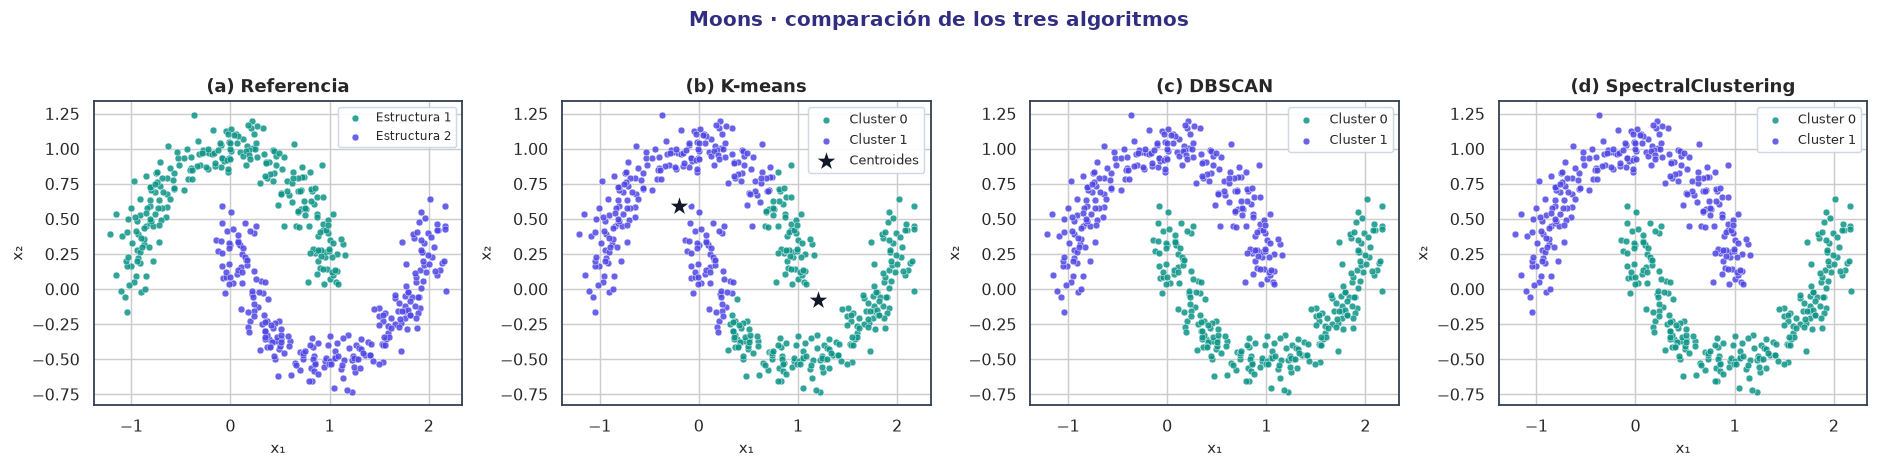

Tabla de resultados guardada en: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados/metricas/moons_resultados.csv


,Dataset,Algoritmo,Clusters,Ruido,ARI,V-medida,Silueta,Davies-Bouldin
0,Moons,K-means,2,0,0.265,0.202,0.483,0.789
1,Moons,DBSCAN,2,0,1.000,1.000,0.327,1.156
2,Moons,Spectral,2,0,1.000,1.000,0.327,1.156


Figura guardada en: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados/graficas/moons_metricas.png


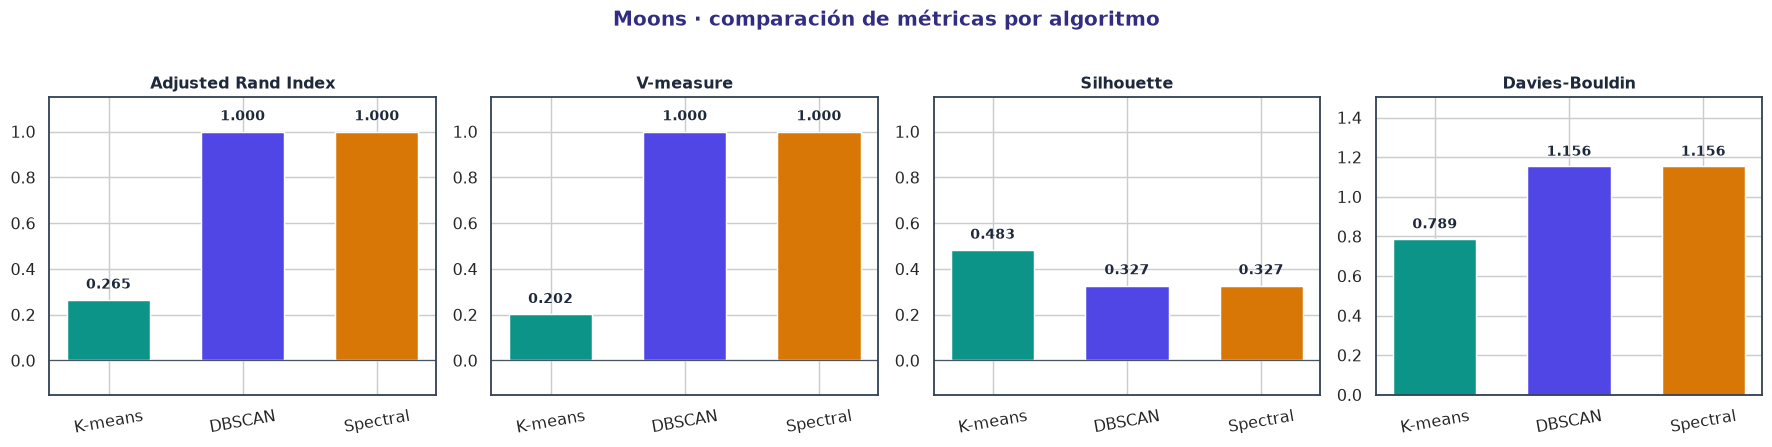

In [ ]:
# =====================================================================
# 06.9 · Comparación visual y de métricas sobre Moons
# =====================================================================
fig, ejes = plt.subplots(1, 4, figsize=(18.0, 4.5))

eje = ejes[0]
for etiqueta, color, nombre in ((0, PALETA_CLUSTER[0], "Estructura 1"),
                                (1, PALETA_CLUSTER[1], "Estructura 2")):
    mascara = y_moons == etiqueta
    eje.scatter(X_moons[mascara, 0], X_moons[mascara, 1], s=22, c=color,
                alpha=0.85, edgecolors="white", linewidths=0.3, label=nombre)
eje.set_title("(a) Referencia")
eje.legend(fontsize=8)

scatter_clusters(ejes[1], X_moons, etiquetas_kmeans_moons,
                 "(b) K-means", tamanos=22,
                 centroides=kmeans_moons.cluster_centers_)
scatter_clusters(ejes[2], X_moons, etiquetas_dbscan_moons,
                 "(c) DBSCAN", tamanos=22)
scatter_clusters(ejes[3], X_moons, etiquetas_spectral_moons,
                 "(d) SpectralClustering", tamanos=22)

for eje in ejes.flat:
    eje.set_xlabel("x₁"); eje.set_ylabel("x₂")
fig.suptitle("Moons · comparación de los tres algoritmos",
             fontsize=14, fontweight="bold", color=INDIGO_OSCURO)
fig.tight_layout(rect=(0, 0, 1, 0.95))
print("Figura guardada en:", guardar_figura(fig, "moons_comparacion"))
plt.show()

tabla_resultados_moons = pd.DataFrame([f for f in RESULTADOS if f["Dataset"] == "Moons"])
print("Tabla de resultados guardada en:",
      guardar_tabla(tabla_resultados_moons, "moons_resultados"))
display(tabla_resultados_moons.drop(columns=["Hiperparámetros"]).round(3))
figura_comparacion_metricas(tabla_resultados_moons,
                            "Moons · comparación de métricas por algoritmo",
                            "moons_metricas")

### 06.10 · Análisis de Moons: ¿qué algoritmo funciona mejor y por qué?

**K-means falla por diseño, no por mala calibración.** Con $K=2$ coloca los centroides en el centro geométrico de cada mitad del plano y traza una **frontera lineal** entre ambos: la partición corta las dos lunas a la mitad. Su ARI (0.265) y su V-measure (0.202) frente a la referencia cuantifican ese error: no es que K-means esté mal calibrado, es que **el modelo, que minimiza la varianza intra-cluster respecto de centroides, no puede representar dos estructuras cóncavas entrelazadas**.

**DBSCAN resuelve el problema por densidad.** Con `eps=0.2` recupera exactamente las dos lunas (ARI = 1.0, V-measure = 1.0): dentro de cada luna los puntos forman regiones de densidad conectada y el hueco central entre lunas es una zona de baja densidad que actúa de frontera natural. La ausencia de ruido con la configuración elegida indica además que el radio está dentro de la ventana estable del algoritmo.

**SpectralClustering resuelve el problema por similitud.** Con afinidad de 10 vecinos, cada luna se convierte en una componente conexa del grafo y el corte espectral la separa limpiamente (ARI = 1.0, V-measure = 1.0). La estructura del grafo hace el trabajo que la distancia a centroides no puede hacer.

**La advertencia más importante del experimento: la silueta se equivoca.** La partición de K-means sobre Moons tiene la **silueta más alta** del dataset (0.483, frente a 0.327 de DBSCAN y SpectralClustering) y aun así es la **incorrecta**. La silueta compara distancias medias intra/inter-cluster y premia blobs compactos y convexos: cortar una media luna por la mitad produce dos grupos compactos que la métrica "premia". Davies-Bouldin muestra el mismo sesgo (0.789 para la partición incorrecta de K-means frente a 1.156 para las correctas). Las métricas internas, por sí solas, **no bastan para validar estructura** en datos no convexos; la validación externa (cuando existe referencia) y el razonamiento geométrico sobre el dominio son imprescindibles.


---
## 07 · Experimento 3 — Dataset Circles
---

El dataset sintético **Circles** se genera con `make_circles` y contiene dos **anillos concéntricos** (un disco interior y un anillo exterior). Es el caso límite de estructura no convexa: los dos grupos son **anidados** — el centroide global de ambos anillos es prácticamente el mismo punto, de modo que cualquier método basado en distancias a un centro o en fronteras lineales es estructuralmente incapaz de separarlos.

**Configuración de generación (reproducible):** `make_circles(n_samples=500, factor=0.4, noise=0.08, random_state=42)`. El `factor = 0.4` fija el radio del anillo interior al 40 % del exterior. Las etiquetas del generador (anillo interior / anillo exterior) se usan **solo** para validación externa. Como en Moons, las dos características están en escalas comparables y los modelos se entrenan sobre las coordenadas originales sin reescalar.


Forma de X_circles: (500, 2)
Puntos por estructura: [250 250]


Figura guardada en: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados/graficas/circles_original.png


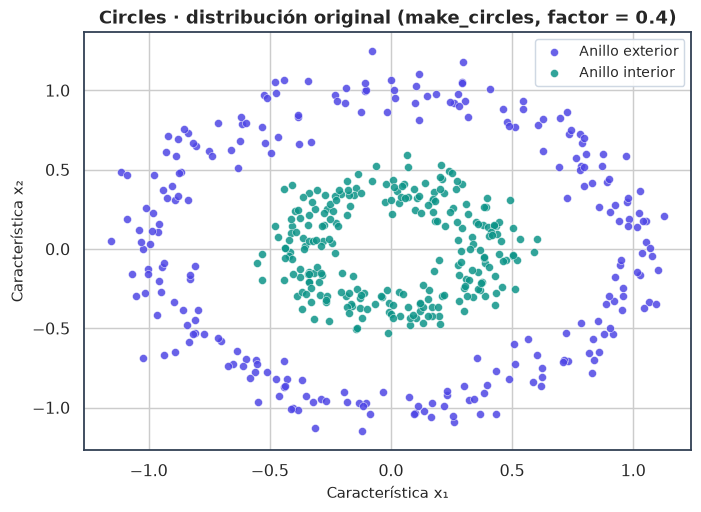

In [ ]:
# =====================================================================
# 07.1 · Generación de Circles y distribución original
# =====================================================================
X_circles, y_circles = make_circles(n_samples=500, factor=0.4, noise=0.08,
                                    random_state=SEED)
print("Forma de X_circles:", X_circles.shape)
print("Puntos por estructura:", np.bincount(y_circles))

fig, eje = plt.subplots(figsize=(6.8, 5.0))
for etiqueta, color, nombre in ((0, PALETA_CLUSTER[1], "Anillo exterior"),
                                (1, PALETA_CLUSTER[0], "Anillo interior")):
    mascara = y_circles == etiqueta
    eje.scatter(X_circles[mascara, 0], X_circles[mascara, 1], s=30, c=color,
                alpha=0.85, edgecolors="white", linewidths=0.35, label=nombre)
eje.set_xlabel("Característica x₁")
eje.set_ylabel("Característica x₂")
eje.set_title("Circles · distribución original (make_circles, factor = 0.4)")
eje.legend()
fig.tight_layout()
print("Figura guardada en:", guardar_figura(fig, "circles_original"))
plt.show()

Tabla del codo guardada en: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados/metricas/circles_codo_kmeans.csv


,K,Inercia,Silueta
0,1,293.784,NaN
1,2,192.067,0.328
2,3,123.876,0.350
3,4,93.385,0.334
4,5,77.404,0.311
5,6,66.054,0.344
6,7,55.476,0.385
7,8,45.694,0.410


Figura guardada en: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados/graficas/circles_elbow.png


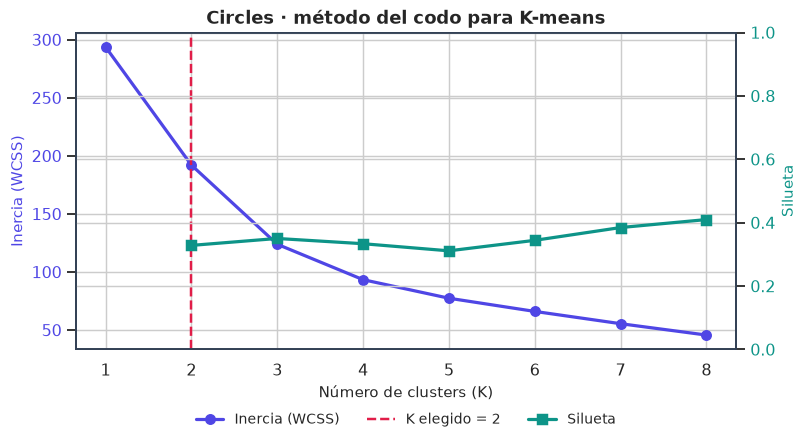

In [ ]:
# =====================================================================
# 07.2 · Método del codo para K-means sobre Circles
# =====================================================================
tabla_codo_circles = metodo_codo(X_circles, range(1, 9))
print("Tabla del codo guardada en:",
      guardar_tabla(tabla_codo_circles, "circles_codo_kmeans"))
display(tabla_codo_circles.round(3))
figura_codo(tabla_codo_circles, k_elegido=2,
            titulo="Circles · método del codo para K-means",
            archivo="circles_elbow")

**Selección de $K$ en Circles.** Como en Moons, la mayor caída de inercia ocurre de $K=1$ a $K=2$ (294 → 192) y la curva se aplana después: el codo indica **$K = 2$**, coherente con el generador (dos anillos concéntricos). De nuevo la silueta interna prefiere valores de $K$ mayores (0.410 con $K=8$), ya que cortar los anillos en arcos convexos la maximiza — el mismo sesgo ya documentado en Moons. Se entrena K-means con $K=2$, `n_init=10` y `random_state=42`.


Figura guardada en: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados/graficas/circles_kmeans.png


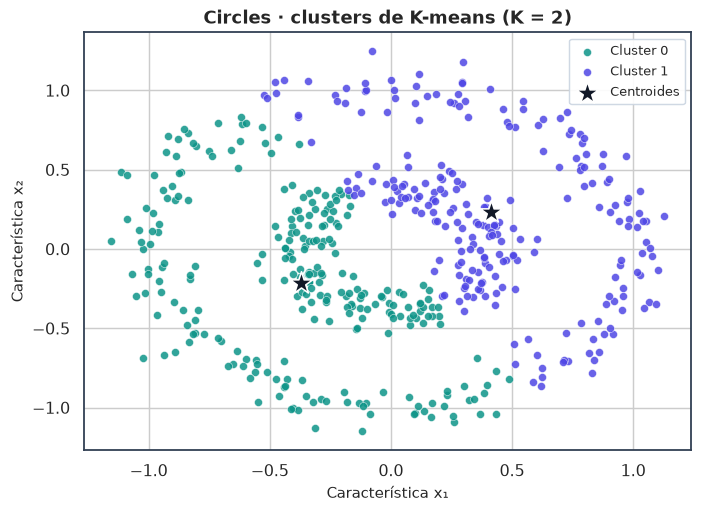

Dataset,Algoritmo,Clusters,Ruido,ARI,V-medida,Silueta,Davies-Bouldin
Circles,K-means,2,0,-0.002,0.000,0.328,1.221


In [ ]:
# =====================================================================
# 07.3 · K-means sobre Circles (K = 2)
# =====================================================================
kmeans_circles = KMeans(n_clusters=2, n_init=10, random_state=SEED)
etiquetas_kmeans_circles = kmeans_circles.fit_predict(X_circles)

fig, eje = plt.subplots(figsize=(6.8, 5.0))
scatter_clusters(eje, X_circles, etiquetas_kmeans_circles,
                 "Circles · clusters de K-means (K = 2)",
                 centroides=kmeans_circles.cluster_centers_)
eje.set_xlabel("Característica x₁")
eje.set_ylabel("Característica x₂")
fig.tight_layout()
print("Figura guardada en:", guardar_figura(fig, "circles_kmeans"))
plt.show()

fila_kmeans_circles = registrar_resultado(
    "Circles", "K-means", "n_clusters=2, n_init=10, random_state=42",
    X_circles, etiquetas_kmeans_circles, y_circles)
display(mostrar_fila(fila_kmeans_circles))

Figura guardada en: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados/graficas/circles_dbscan_kdist.png


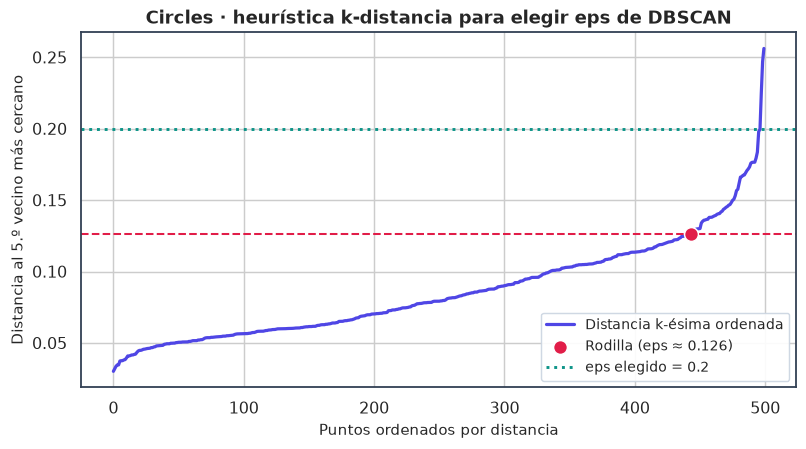

Valor de la rodilla detectada: eps ≈ 0.126
Barrido guardado en: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados/metricas/circles_dbscan_barrido.csv


,eps,min_samples,Clusters,Ruido,Ruido (%),Silueta*,Davies-Bouldin*
0,0.08,5,15,174,34.8,0.292,0.506
1,0.08,10,7,347,69.4,0.532,0.527
2,0.10,5,18,70,14.0,0.277,0.594
3,0.10,10,2,263,52.6,0.391,1.114
4,0.12,5,7,15,3.0,0.283,0.777
5,0.12,10,5,191,38.2,0.347,0.517
6,0.15,5,3,3,0.6,0.090,36.755
7,0.15,10,13,36,7.2,0.268,0.630
8,0.18,5,2,1,0.2,0.152,180.190
9,0.18,10,3,8,1.6,0.250,1.844


In [ ]:
# =====================================================================
# 07.4 · Heurística k-distancia y barrido de DBSCAN sobre Circles
# =====================================================================
rodilla_circles = figura_kdistancia(
    X_circles, min_samples=5, eps_elegido=0.2,
    titulo="Circles · heurística k-distancia para elegir eps de DBSCAN",
    archivo="circles_dbscan_kdist")
print(f"Valor de la rodilla detectada: eps ≈ {rodilla_circles:.3f}")

tabla_dbscan_circles = barrido_dbscan(
    X_circles,
    valores_eps=[0.08, 0.10, 0.12, 0.15, 0.18, 0.20, 0.25, 0.30],
    valores_min_samples=[5, 10])
print("Barrido guardado en:",
      guardar_tabla(tabla_dbscan_circles, "circles_dbscan_barrido"))
display(tabla_dbscan_circles.round(3))

**Lectura del barrido de DBSCAN en Circles.** La rodilla está en `eps ≈ 0.13`, pero ese radio es apenas suficiente para la densidad del anillo **interior**, que al tener menor perímetro es más denso en distancia angular: con `eps ≤ 0.15` el anillo interior queda cortado en varios fragmentos (3–18 clusters) porque el radio no alcanza a recorrer todo el perímetro con densidad continua. En la ventana `eps ∈ [0.18, 0.20]` la partición se estabiliza en **2 clusters** (los dos anillos completos) con ruido residual mínimo; en `eps = 0.25` el radio cruza el hueco entre anillos y todo colapsa en un único cluster (silueta sin definir, registrada como `NaN`).

**Decisión documentada:** `eps = 0.2`, `min_samples = 5`, centro de la ventana estable: 2 clusters, 0 puntos de ruido, margen tanto contra la sobre-segmentación (por debajo) como contra la fusión (por encima). La elección usa la k-distancia y la estabilidad de la partición, no las etiquetas.


Conteo de puntos por etiqueta (-1 = ruido):
0    250
1    250


Figura guardada en: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados/graficas/circles_dbscan.png


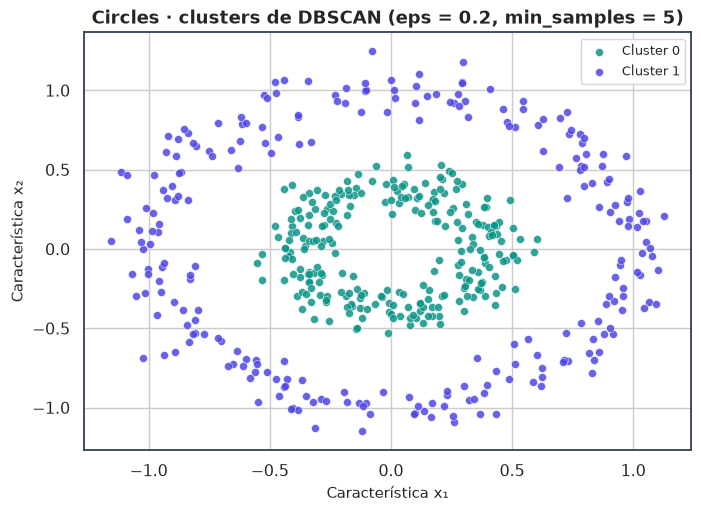

Dataset,Algoritmo,Clusters,Ruido,ARI,V-medida,Silueta,Davies-Bouldin
Circles,DBSCAN,2,0,1.000,1.000,0.152,128.945


In [ ]:
# =====================================================================
# 07.5 · DBSCAN final sobre Circles (eps = 0.2, min_samples = 5)
# =====================================================================
dbscan_circles = DBSCAN(eps=0.2, min_samples=5)
etiquetas_dbscan_circles = dbscan_circles.fit_predict(X_circles)

print("Conteo de puntos por etiqueta (-1 = ruido):")
print(pd.Series(etiquetas_dbscan_circles).value_counts().sort_index().to_string())

fig, eje = plt.subplots(figsize=(6.8, 5.0))
scatter_clusters(eje, X_circles, etiquetas_dbscan_circles,
                 "Circles · clusters de DBSCAN (eps = 0.2, min_samples = 5)")
eje.set_xlabel("Característica x₁")
eje.set_ylabel("Característica x₂")
fig.tight_layout()
print("Figura guardada en:", guardar_figura(fig, "circles_dbscan"))
plt.show()

fila_dbscan_circles = registrar_resultado(
    "Circles", "DBSCAN", "eps=0.2, min_samples=5",
    X_circles, etiquetas_dbscan_circles, y_circles)
display(mostrar_fila(fila_dbscan_circles))

In [ ]:
# =====================================================================
# 07.6 · Barrido y selección de SpectralClustering sobre Circles
# =====================================================================
configuraciones_spectral_circles = (
    [{"n_clusters": 2, "affinity": "rbf", "gamma": g}
     for g in (1.0, 5.0, 10.0, 30.0, 100.0)]
    + [{"n_clusters": 2, "affinity": "nearest_neighbors", "n_neighbors": n}
       for n in (5, 10, 15)]
)
tabla_spectral_circles = barrido_spectral(X_circles, configuraciones_spectral_circles)
print("Barrido guardado en:",
      guardar_tabla(tabla_spectral_circles, "circles_spectral_barrido"))
display(tabla_spectral_circles.round(3))

Barrido guardado en: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados/metricas/circles_spectral_barrido.csv


,Configuración,Grafo conexo,Clusters,Ruido,Silueta,Davies-Bouldin
0,"n_clusters=2, affinity=rbf, gamma=1.0",Sí,2,0,0.328,1.220
1,"n_clusters=2, affinity=rbf, gamma=5.0",Sí,2,0,0.329,1.215
2,"n_clusters=2, affinity=rbf, gamma=10.0",Sí,2,0,0.327,1.218
3,"n_clusters=2, affinity=rbf, gamma=30.0",Sí,2,0,0.152,128.945
4,"n_clusters=2, affinity=rbf, gamma=100.0",Sí,2,0,0.152,128.945
5,"n_clusters=2, affinity=nearest_neighbors, n_ne...",No,2,0,0.152,128.945
6,"n_clusters=2, affinity=nearest_neighbors, n_ne...",Sí,2,0,0.152,128.945
7,"n_clusters=2, affinity=nearest_neighbors, n_ne...",Sí,2,0,0.152,128.945


**Decisión documentada.** Igual que en Moons, se selecciona `affinity='nearest_neighbors'`, `n_neighbors=10`, `k=2`: la conectividad local recorre cada anillo como una "cadena" de vecinos y el corte espectral separa las dos componentes. La configuración es robusta para 5, 10 y 15 vecinos. El barrido RBF vuelve a mostrar el fenómeno de bandas: con $\gamma$ pequeño el kernel es demasiado ancho y la partición decae a un corte lineal tipo K-means (partición diametral de los anillos); se requiere un $\gamma$ grande para que el kernel sea suficientemente local, una calibración delicada que la afinidad de vecinos evita por completo.


Figura guardada en: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados/graficas/circles_spectral.png


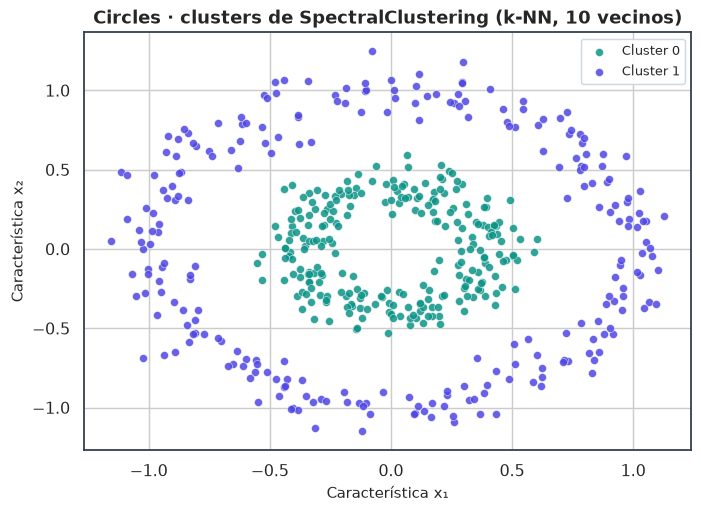

Dataset,Algoritmo,Clusters,Ruido,ARI,V-medida,Silueta,Davies-Bouldin
Circles,Spectral,2,0,1.000,1.000,0.152,128.945


In [ ]:
# =====================================================================
# 07.7 · SpectralClustering final sobre Circles (k-NN, 10 vecinos)
# =====================================================================
spectral_circles = SpectralClustering(n_clusters=2, affinity="nearest_neighbors",
                                      n_neighbors=10, random_state=SEED)
etiquetas_spectral_circles = spectral_circles.fit_predict(X_circles)

fig, eje = plt.subplots(figsize=(6.8, 5.0))
scatter_clusters(eje, X_circles, etiquetas_spectral_circles,
                 "Circles · clusters de SpectralClustering (k-NN, 10 vecinos)")
eje.set_xlabel("Característica x₁")
eje.set_ylabel("Característica x₂")
fig.tight_layout()
print("Figura guardada en:", guardar_figura(fig, "circles_spectral"))
plt.show()

fila_spectral_circles = registrar_resultado(
    "Circles", "Spectral", "n_clusters=2, affinity=nearest_neighbors, n_neighbors=10",
    X_circles, etiquetas_spectral_circles, y_circles)
display(mostrar_fila(fila_spectral_circles))

Figura guardada en: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados/graficas/circles_comparacion.png


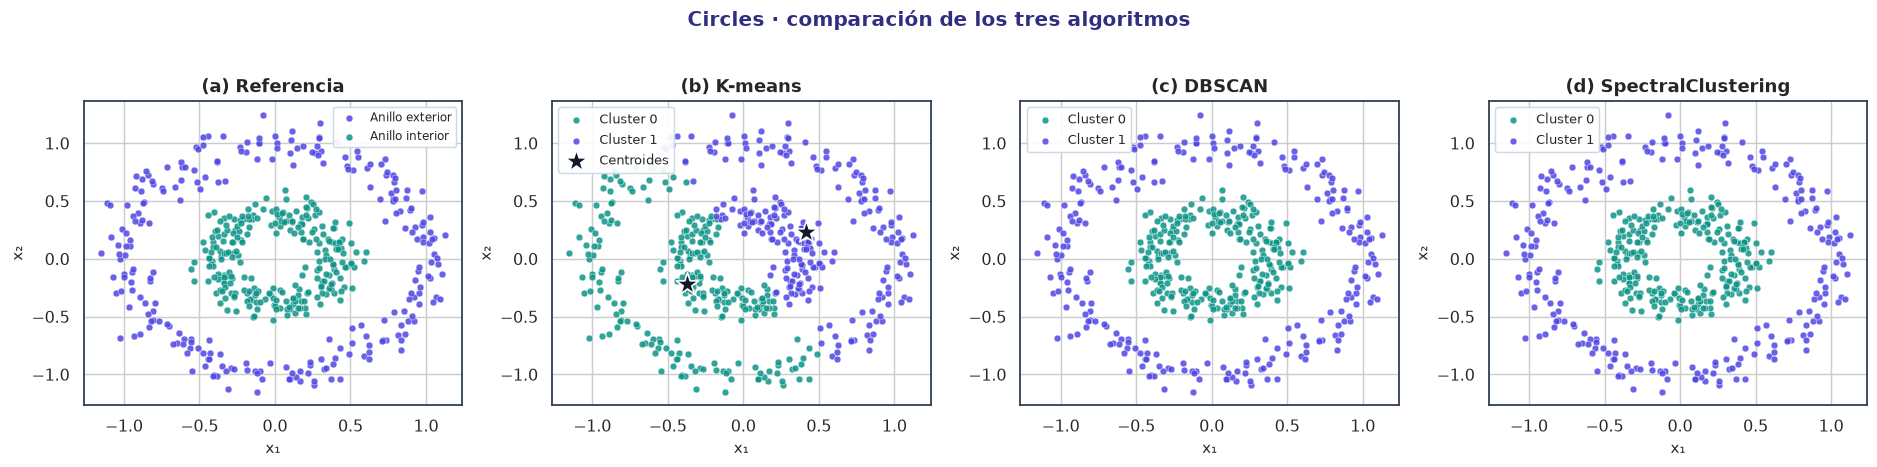

Tabla de resultados guardada en: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados/metricas/circles_resultados.csv


,Dataset,Algoritmo,Clusters,Ruido,ARI,V-medida,Silueta,Davies-Bouldin
0,Circles,K-means,2,0,-0.002,0.0,0.328,1.221
1,Circles,DBSCAN,2,0,1.000,1.0,0.152,128.945
2,Circles,Spectral,2,0,1.000,1.0,0.152,128.945


Figura guardada en: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados/graficas/circles_metricas.png


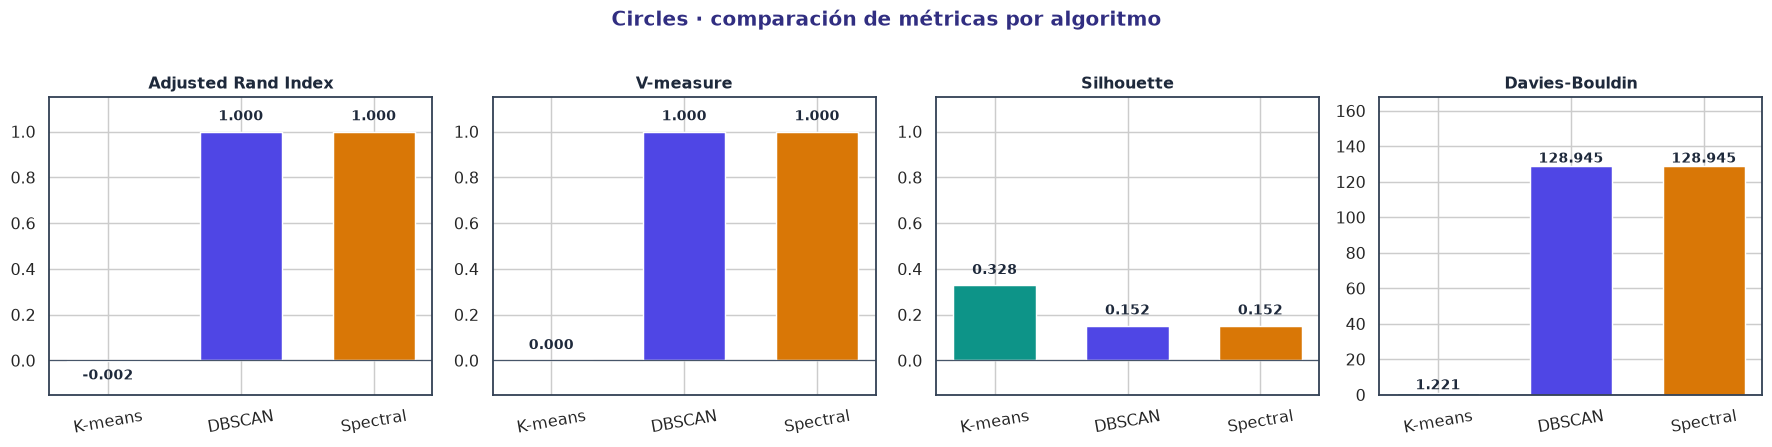

In [ ]:
# =====================================================================
# 07.8 · Comparación visual y de métricas sobre Circles
# =====================================================================
fig, ejes = plt.subplots(1, 4, figsize=(18.0, 4.5))

eje = ejes[0]
for etiqueta, color, nombre in ((0, PALETA_CLUSTER[1], "Anillo exterior"),
                                (1, PALETA_CLUSTER[0], "Anillo interior")):
    mascara = y_circles == etiqueta
    eje.scatter(X_circles[mascara, 0], X_circles[mascara, 1], s=22, c=color,
                alpha=0.85, edgecolors="white", linewidths=0.3, label=nombre)
eje.set_title("(a) Referencia")
eje.legend(fontsize=8)

scatter_clusters(ejes[1], X_circles, etiquetas_kmeans_circles,
                 "(b) K-means", tamanos=22,
                 centroides=kmeans_circles.cluster_centers_)
scatter_clusters(ejes[2], X_circles, etiquetas_dbscan_circles,
                 "(c) DBSCAN", tamanos=22)
scatter_clusters(ejes[3], X_circles, etiquetas_spectral_circles,
                 "(d) SpectralClustering", tamanos=22)

for eje in ejes.flat:
    eje.set_xlabel("x₁"); eje.set_ylabel("x₂")
fig.suptitle("Circles · comparación de los tres algoritmos",
             fontsize=14, fontweight="bold", color=INDIGO_OSCURO)
fig.tight_layout(rect=(0, 0, 1, 0.95))
print("Figura guardada en:", guardar_figura(fig, "circles_comparacion"))
plt.show()

tabla_resultados_circles = pd.DataFrame([f for f in RESULTADOS
                                         if f["Dataset"] == "Circles"])
print("Tabla de resultados guardada en:",
      guardar_tabla(tabla_resultados_circles, "circles_resultados"))
display(tabla_resultados_circles.drop(columns=["Hiperparámetros"]).round(3))
figura_comparacion_metricas(tabla_resultados_circles,
                            "Circles · comparación de métricas por algoritmo",
                            "circles_metricas")

### 07.9 · Análisis de Circles

**K-means produce su peor resultado.** Los centroides de los dos clusters caen prácticamente sobre el centro geométrico común de ambos anillos y la frontera lineal resultante divide los anillos en dos semicírculos opuestos: cada cluster contiene la mitad de cada anillo. El ARI prácticamente nulo (−0.002) y el V-measure cercano a cero (0.0003) cuantifican que la partición no guarda **ninguna** relación con la estructura real: es el fallo estructural máximo esperable de un modelo de fronteras lineales ante grupos anidados.

**DBSCAN separa los anillos por densidad.** Con `eps = 0.2` los dos anillos son dos regiones de densidad conectada separadas por el hueco radial: DBSCAN los recupera exactamente (ARI = 1.0, V-measure = 1.0). El barrido muestra, además, la sensibilidad del método: por debajo de la ventana estable el anillo interior se fragmenta (los arcos densos no alcanzan a conectarse) y por encima todo se fusiona.

**SpectralClustering separa los anillos por conectividad.** Con afinidad de 10 vecinos, cada anillo es una componente conexa del grafo de similitud y el corte espectral los separa con exactitud (ARI = 1.0, V-measure = 1.0). Este es el ejemplo más claro de que el método "desenrolla" la geometría: el embedding espectral coloca a los puntos de cada anillo en direcciones distintas y un K-means lineal **en ese nuevo espacio** basta para separarlos.

**Sobre las métricas internas.** Como en Moons, la silueta de K-means (0.328) es **superior** a la de las particiones correctas de DBSCAN y SpectralClustering (0.152): la partición diametral produce dos mitades compactas y equilibradas, que es exactamente lo que la silueta premia. El índice Davies-Bouldin lleva el sesgo al extremo: la partición incorrecta de K-means obtiene el mejor valor del dataset (1.22) y las particiones correctas un valor enorme (≈ 128.9). La razón es geométrica y muy ilustrativa: los centroides de dos anillos concéntricos **prácticamente coinciden** ($M_{ij} \approx 0$), y al dividir la dispersión entre esa distancia casi nula el índice se dispara aunque la partición sea perfecta. Ninguna métrica interna basada en centroides debe interpretarse sola cuando la estructura es anidada; la validación externa resulta imprescindible para no caer en esa trampa.


---
## 08 · Comparación general de los tres datasets
---

La tabla siguiente consolida **todas las ejecuciones reales** registradas durante el notebook: algoritmo, dataset, número de clusters detectados, puntos marcados como ruido, ARI, V-measure, Silueta y Davies-Bouldin. Recuérdese que las métricas internas de cada fila se calcularon sobre el espacio de características usado para entrenar ese modelo (Iris: 4 características estandarizadas; Moons y Circles: 2 coordenadas originales), por lo que **no deben compararse entre datasets** sin esa advertencia.


In [ ]:
# =====================================================================
# 08.1 · Tabla consolidada de los nueve experimentos
# =====================================================================
tabla_resumen = pd.DataFrame(RESULTADOS)
orden_datasets = ["Iris", "Moons", "Circles"]
tabla_resumen["Dataset"] = pd.Categorical(tabla_resumen["Dataset"],
                                          categories=orden_datasets,
                                          ordered=True)
tabla_resumen = tabla_resumen.sort_values(["Dataset", "Algoritmo"]).reset_index(drop=True)

columnas_resumen = ["Dataset", "Algoritmo", "Clusters", "Ruido",
                     "ARI", "V-medida", "Silueta", "Davies-Bouldin"]
print("Tabla resumen guardada en:",
      guardar_tabla(tabla_resumen, "resumen_general", subdirectorio="tablas"))
print("Tabla de hiperparámetros guardada en:",
      guardar_tabla(tabla_resumen[["Dataset", "Algoritmo", "Hiperparámetros",
                                   "Clusters", "Ruido"]],
                   "hiperparametros", subdirectorio="tablas"))
display(tabla_resumen[columnas_resumen].round(3))

# Resumen JSON con todos los números clave (fuente del informe)
with open(os.path.join(DIR_METRICAS, "resumen_experimentos.json"), "w",
          encoding="utf-8") as archivo:
    json.dump(RESULTADOS, archivo, ensure_ascii=False, indent=2, default=float)
print("Resumen JSON guardado en:",
      os.path.join(DIR_METRICAS, "resumen_experimentos.json"))

Tabla resumen guardada en: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados/tablas/resumen_general.csv
Tabla de hiperparámetros guardada en: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados/tablas/hiperparametros.csv


,Dataset,Algoritmo,Clusters,Ruido,ARI,V-medida,Silueta,Davies-Bouldin
0,Iris,DBSCAN,2,6,0.540,0.671,0.602,0.557
1,Iris,K-means,3,0,0.620,0.659,0.460,0.834
2,Iris,Spectral,3,0,0.564,0.717,0.495,0.534
3,Moons,DBSCAN,2,0,1.000,1.000,0.327,1.156
4,Moons,K-means,2,0,0.265,0.202,0.483,0.789
5,Moons,Spectral,2,0,1.000,1.000,0.327,1.156
6,Circles,DBSCAN,2,0,1.000,1.000,0.152,128.945
7,Circles,K-means,2,0,-0.002,0.000,0.328,1.221
8,Circles,Spectral,2,0,1.000,1.000,0.152,128.945


Resumen JSON guardado en: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados/metricas/resumen_experimentos.json


Figura guardada en: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados/graficas/comparacion_general_metricas.png


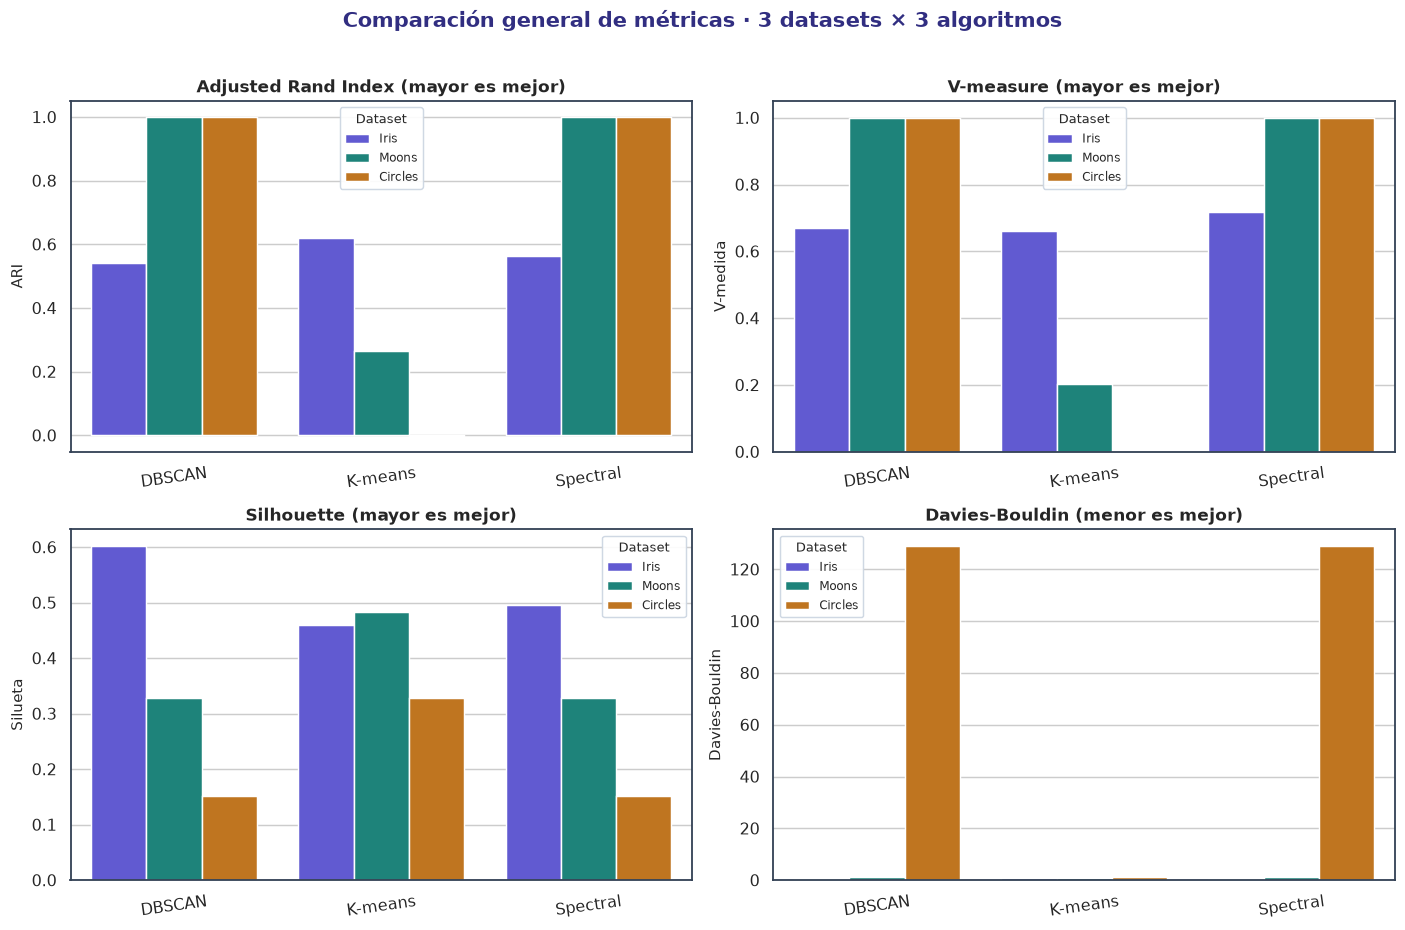

Figura guardada en: /home/ccunurana/Documentos/Aprendizaje Maquina/Tarea 4/resultados/graficas/comparacion_ari_heatmap.png


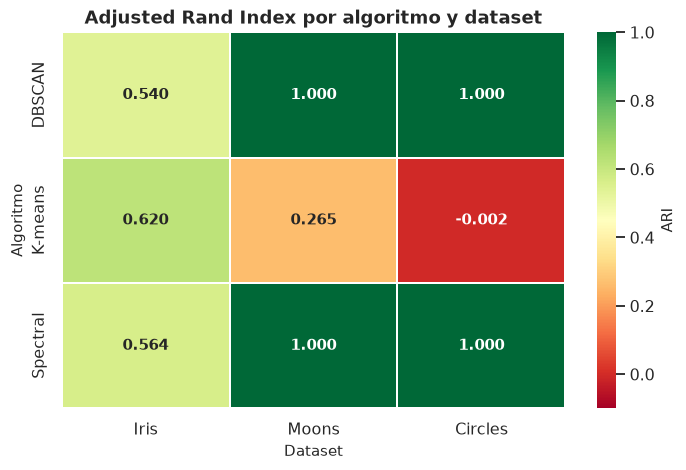

In [ ]:
# =====================================================================
# 08.2 · Gráficos comparativos de las métricas (todos los datasets)
# =====================================================================
fig, ejes = plt.subplots(2, 2, figsize=(13.5, 9.0))
metricas = [("ARI", "Adjusted Rand Index (mayor es mejor)"),
            ("V-medida", "V-measure (mayor es mejor)"),
            ("Silueta", "Silhouette (mayor es mejor)"),
            ("Davies-Bouldin", "Davies-Bouldin (menor es mejor)")]

for eje, (metrica, rotulo) in zip(ejes.flat, metricas):
    datos = tabla_resumen.dropna(subset=[metrica])
    sns.barplot(data=datos, x="Algoritmo", y=metrica, hue="Dataset",
                palette=PALETA_DATASETS, ax=eje, edgecolor="white")
    eje.set_title(rotulo, fontsize=11.5)
    eje.set_xlabel("")
    eje.tick_params(axis="x", rotation=8)
    eje.legend(title="Dataset", fontsize=8.5, title_fontsize=9)
fig.suptitle("Comparación general de métricas · 3 datasets × 3 algoritmos",
             fontsize=14.5, fontweight="bold", color=INDIGO_OSCURO)
fig.tight_layout(rect=(0, 0, 1, 0.965))
print("Figura guardada en:", guardar_figura(fig, "comparacion_general_metricas"))
plt.show()

# Mapa de calor del ARI
tabla_ari = tabla_resumen.pivot_table(index="Algoritmo", columns="Dataset",
                                      values="ARI")
tabla_ari = tabla_ari.reindex(columns=orden_datasets)
fig, eje = plt.subplots(figsize=(6.8, 4.6))
sns.heatmap(tabla_ari, annot=True, fmt=".3f", cmap="RdYlGn", vmin=-0.1,
            vmax=1.0, ax=eje, cbar_kws={"label": "ARI"},
            linewidths=1.2, linecolor="white", annot_kws={"fontweight": "bold"})
eje.set_title("Adjusted Rand Index por algoritmo y dataset")
fig.tight_layout()
print("Figura guardada en:", guardar_figura(fig, "comparacion_ari_heatmap"))
plt.show()

**Lectura de la comparación general.** Tres patrones emergen de la tabla consolidada:

1. **K-means** es competitivo en Iris (estructura mayormente separable en el espacio estandarizado) y colapsa en los datasets no convexos: su ARI pasa de un acuerdo moderado en Iris a ≈ 0.27 en Moons y ≈ 0 en Circles.
2. **DBSCAN** recupera con exactitud las estructuras de Moons y Circles (ARI = 1.0 en ambos) y ofrece en Iris una partición de 2 clusters que refleja la geometría de densidad real del dataset (con un pequeño porcentaje de ruido correctamente identificado en la zona de solapamiento).
3. **SpectralClustering** con afinidad de vecinos recupera exactamente Moons y Circles y, con `k=3` y RBF en Iris, produce una partición comparable a la de K-means.

El contraste entre las columnas de métricas internas y externas en Moons y Circles constituye el hallazgo metodológico central: **las particiones incorrectas de K-means obtienen las mejores siluetas y los mejores Davies-Bouldin** de esos datasets, mientras las particiones correctas obtienen valores internos modestos. Ninguna métrica interna debe interpretarse sin atender al sesgo convexo que comparten.


---
## 09 · Análisis de naturaleza lineal y no lineal
---

### ¿Qué modelos son considerados lineales?

**K-means.** Su regla de asignación es $k(x) = \arg\min_i \|x - \mu_i\|^2$: cada punto va al centroide más cercano. La frontera entre los clusters $i$ y $j$ es el conjunto $\{x : \|\mu_i - x\| = \|\mu_j - x\|\}$, que es un **hiperplano perpendicular al segmento $\mu_i\mu_j$** (las caras de la teselación de Voronoi). Bajo la métrica euclidiana en el espacio original, K-means produce particiones por cortes lineales y, por tanto, clusters convexos. Esa es su naturaleza de **modelo lineal** en el sentido geométrico del clustering: no significa que "solo sirva para datos lineales", sino que **el repertorio de fronteras que puede trazar está limitado a hiperplanos**.

### ¿Qué modelos pueden detectar estructuras no lineales?

**DBSCAN y SpectralClustering.** Ninguno de los dos define los clusters mediante distancia a un centro:

- DBSCAN define un cluster como un conjunto **maximal de puntos conectados por densidad** (cadenas de puntos núcleo dentro de radio `eps`). La forma del cluster emerge de la distribución empírica de los puntos, no de una función de frontera global: las regiones pueden ser cóncavas, anulares o serpenteadas.
- SpectralClustering define los clusters como **cortes de un grafo de similitud**. Aplica K-means (lineal) pero **sobre el espacio espectral** (los primeros autovectores del Laplaciano), un espacio transformado donde la estructura no lineal del grafo queda "desenrollada": las fronteras efectivas en el espacio original pueden ser arbitrariamente complejas.

### ¿Por qué K-means tiene dificultades con Moons y Circles?

Porque sus fronteras son hiperplanos y sus clusters, regiones convexas. En **Moons**, las dos estructuras cóncavas entrelazadas obligan a K-means a cortar cada luna por la mitad para equilibrar la varianza intra-cluster (ARI ≈ 0.27). En **Circles**, los dos anillos comparten el mismo centro geométrico, así que cualquier línea divisoria produce dos mitades simétricas que mezclan ambos anillos (ARI ≈ 0). No es un problema de calibración: con $K=2$ correcto y `n_init=10`, el **modelo** no tiene representación para esas estructuras.

### ¿Por qué DBSCAN puede reconocer estructuras no convexas?

Porque su noción de cluster es **topológica antes que métrica**: dos puntos pertenecen al mismo cluster si existe una **cadena de puntos densos** que los conecte (`eps` y `min_samples` definen "denso"). La frontera entre clusters es simplemente una región de baja densidad, sea cual sea su forma. En Moons, el hueco entre las lunas; en Circles, el espacio radial entre anillos. Además, DBSCAN no necesita fijar el número de clusters: los descubre, y degrada con elegancia marcando como **ruido** los puntos que no encajan en ninguna región densa.

### ¿Por qué SpectralClustering puede detectar estructuras complejas?

Porque la información de "pertenencia" viaja por el **grafo**, no por la distancia a centros. Con afinidad de $k$ vecinos, cada luna o cada anillo es una componente casi conexa del grafo; el análisis espectral de la matriz Laplaciana produce un embedding donde esas componentes quedan separadas (aproximadamente en autovectores distintos), y un K-means lineal en ese espacio resuelve el problema. La **matriz de similitud** es el objeto crítico: mal calibrada (RBF con $\gamma$ inadecuado) el grafo mezcla o fragmenta la estructura; bien calibrada (conectividad local de vecinos) el método es robusto.

### ¿Qué hiperparámetros son críticos para el entrenamiento exitoso?

| Algoritmo | Hiperparámetros críticos | Papel | Riesgo si se calibran mal |
|:--|:--|:--|:--|
| **K-means** | `n_clusters` | Número de particiones (debe fijarse a priori) | Fusiona o fragmenta grupos reales |
| | `n_init` | Reinicios de la inicialización | Mínimos locales (inercia alta) |
| | `random_state` | Reproducibilidad | Resultados no comparables |
| **DBSCAN** | `eps` | Radio de densidad | Pequeño → ruido y fragmentación; grande → fusión en 1 cluster |
| | `min_samples` | Umbral de densidad | Alto → demasiado ruido; bajo → clusters débiles con ruido |
| **SpectralClustering** | `n_clusters` | Número de cortes espectrales | Igual que K-means |
| | `affinity` | Definición de similitud/conectividad | RBF inadecuada decae a cortes lineales o fragmenta el grafo |
| | `gamma` / `n_neighbors` | Localidad de la afinidad | Ancho de banda inadecuado |
| | `assign_labels` | Estrategia en el espacio espectral | Inestabilidad adicional |

**Nota final sobre la naturaleza de los algoritmos.** No debe confundirse la naturaleza del algoritmo con la forma geométrica de los datos: K-means es lineal porque su frontera de decisión es lineal en el espacio original bajo la métrica euclidiana (partición de Voronoi con centroides como medias aritméticas), no porque "sus datos deban ser líneas". DBSCAN es un algoritmo basado en **densidad** y SpectralClustering en **relaciones de similitud y métodos espectrales**; ambos pueden trazar fronteras no lineales, cada uno por un mecanismo distinto. Los experimentos lo verifican cuantitativamente: sobre los mismos Moons, el ARI pasa de ≈ 0.27 (K-means) a 1.0 (DBSCAN y Spectral) sin cambiar los datos, solo el modelo.


---
## 10 · Conclusiones
---

1. **La naturaleza del algoritmo determina qué estructuras puede recuperar, y los experimentos lo cuantifican.** Sobre los mismos datos Moons, el ARI pasa de ≈ 0.27 con K-means a exactamente 1.0 con DBSCAN y SpectralClustering; en Circles, de ≈ 0 con K-means a 1.0 con los otros dos. La frontera de Voronoi de K-means (lineal en el espacio de características) es la causa estructural del fallo ante grupos cóncavos y anidados, y ninguna calibración de `n_init` o `random_state` puede corregirla.

2. **DBSCAN resolvió los dos datasets no convexos con una selección de `eps` basada en la curva k-distancia, sin usar etiquetas.** La rodilla detectada automáticamente (≈ 0.11 en Moons, ≈ 0.13 en Circles) delimitó la región de búsqueda y el análisis de estabilidad de la partición (número de clusters y ruido frente a `eps`) identificó la ventana estable donde ambos datasets quedan perfectamente separados con `eps = 0.2`: la estructura emerge de la densidad, no de una forma impuesta.

3. **SpectralClustering resolvió los mismos problemas por conectividad del grafo de similitud.** Con afinidad de 10 vecinos más cercanos recuperó ambas estructuras exactamente (ARI = V-measure = 1.0) y resultó robusto entre 5 y 15 vecinos; el barrido RBF mostró que un `gamma` inadecuado degrada la partición hacia cortes tipo K-means, evidencia de que la **matriz de similitud**, no el paso final de K-means, es el componente crítico del método.

4. **En Iris ningún algoritmo alcanza un acuerdo externo perfecto, y la causa es geométrica, no algorítmica.** K-means y SpectralClustering aíslan las 50 muestras de *setosa* en un cluster puro; DBSCAN agrupa 48 y marca las 2 restantes como ruido. El solapamiento real entre *versicolor* y *virginica* limita el ARI de los tres métodos (0.620, 0.564 y 0.540) y explica que DBSCAN, que no fija $k$, encuentre naturalmente solo 2 regiones de densidad: los 6 puntos de ruido que marca son 2 *setosa* aisladas y 4 puntos de la zona de solapamiento.

5. **Las métricas internas se equivocaron sistemáticamente sobre los datos no convexos, y ese es el hallazgo metodológico más importante de la actividad.** En Moons y Circles las particiones **incorrectas** de K-means obtuvieron las mejores siluetas (0.483 y 0.328) y los mejores Davies-Bouldin (0.789 y 1.22) del dataset, mientras las particiones correctas de DBSCAN/Spectral obtuvieron siluetas modestas (0.327 y 0.152) e incluso un Davies-Bouldin de ≈ 128.9 en Circles — porque los centroides de los anillos concéntricos coinciden y el índice divide entre una distancia inter-centroide casi nula. Silueta y Davies-Bouldin premian compacidad y convexidad y pueden validar estructuras falsas cuando la geometría real no es convexa.

6. **La validación externa (ARI y V-measure) fue indispensable para discriminar particiones correctas e incorrectas.** El ARI corregido por el azar permitió distinguir un fallo parcial (Moons, 0.265) de un fallo total (Circles, −0.002), y la V-measure explicó *por qué*: en la partición de DBSCAN sobre Iris la completitud se mantiene alta ($c \approx 0.81$: cada especie queda concentrada en un único cluster) pero la homogeneidad cae ($h \approx 0.57$) porque un cluster fusiona *versicolor* y *virginica*, mientras que SpectralClustering logra $c \approx 0.92$ a costa de $h \approx 0.59$ y K-means queda equilibrado ($h \approx c \approx 0.66$).

7. **El método del codo y la silueta pueden entrar en conflicto y la decisión debe documentarse.** En Iris el codo de la inercia indicó $K=3$ mientras la silueta prefirió $K=2$ (consecuencia del solapamiento versicolor/virginica); la selección se justificó con el codo y el conocimiento documentado del problema, dejando registro explícito del desacuerdo en lugar de ocultarlo.

8. **Los casos indefinidos se documentaron, no se maquillaron.** Cuando un `eps` excesivo colapsó DBSCAN en un único cluster (Moons con `eps = 0.30`, Circles con `eps = 0.25`), la silueta y Davies-Bouldin quedaron formalmente sin definición y se registraron como `NaN` con su nota explicativa; sustituirlas por cero habría falseado las tablas.

9. **El ruido de DBSCAN es información, no basura.** En Iris los puntos marcados como ruido se localizaron en la zona de solapamiento entre especies (detección de anomalías gratuita), y en Moons/Circles la fracción de ruido funcionó como indicador de calibración: sirvió para distinguir la región estable de `eps` de las regiones de sobre-segmentación y fusión.

10. **En la práctica, la elección de algoritmo debe seguir a la geometría esperada de los datos.** Para grupos compactos y separables (Iris) K-means es suficiente y barato; para estructuras curvas o anidadas (Moons, Circles) se requiere un método de densidad o espectral, aceptando el costo de calibrar `eps`/`min_samples` o construir la matriz de similitud — y en todos los casos las métricas deben interpretarse por pares (externa + interna), nunca una sola por aislado.


---
## 11 · Referencias
---

**Documentación oficial de scikit-learn:**

1. Pedregosa, F. et al. (2011). *Scikit-learn: Machine Learning in Python*. Journal of Machine Learning Research, 12, 2825–2830. https://jmlr.org/papers/v12/pedregosa11a.html
2. scikit-learn developers. *Clustering — User Guide*. https://scikit-learn.org/stable/modules/clustering.html
3. scikit-learn developers. *API Reference — sklearn.cluster.KMeans*. https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html
4. scikit-learn developers. *API Reference — sklearn.cluster.DBSCAN*. https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html
5. scikit-learn developers. *API Reference — sklearn.cluster.SpectralClustering*. https://scikit-learn.org/stable/modules/generated/sklearn.cluster.SpectralClustering.html
6. scikit-learn developers. *Clustering performance evaluation*. https://scikit-learn.org/stable/modules/clustering.html#clustering-performance-evaluation
7. scikit-learn developers. *API Reference — sklearn.metrics.adjusted_rand_score*. https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html
8. scikit-learn developers. *API Reference — sklearn.metrics.v_measure_score*. https://scikit-learn.org/stable/modules/generated/sklearn.metrics.v_measure_score.html
9. scikit-learn developers. *API Reference — sklearn.metrics.silhouette_score*. https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html
10. scikit-learn developers. *API Reference — sklearn.metrics.davies_bouldin_score*. https://scikit-learn.org/stable/modules/generated/sklearn.metrics.davies_bouldin_score.html

**Trabajos originales de los algoritmos y métricas:**

11. MacQueen, J. (1967). *Some methods for classification and analysis of multivariate observations*. Proc. Fifth Berkeley Symposium on Mathematical Statistics and Probability, 281–297.
12. Ester, M., Kriegel, H.-P., Sander, J. y Xu, X. (1996). *A Density-Based Algorithm for Discovering Clusters in Large Spatial Databases with Noise*. Proc. KDD'96, 226–231.
13. Ng, A. Y., Jordan, M. I. y Weiss, Y. (2001). *On Spectral Clustering: Analysis and an Algorithm*. Advances in Neural Information Processing Systems 14 (NIPS), 849–856.
14. Fisher, R. A. (1936). *The use of multiple measurements in taxonomic problems*. Annals of Eugenics, 7(2), 179–188.
15. Hubert, L. y Arabie, P. (1985). *Comparing partitions*. Journal of Classification, 2(1), 193–218.
16. Rosenberg, A. y Hirschberg, J. (2007). *V-Measure: A conditional entropy-based external cluster evaluation measure*. Proc. EMNLP-CoNLL, 410–420.
17. Rousseeuw, P. J. (1987). *Silhouettes: A graphical aid to the interpretation and validation of cluster analysis*. Journal of Computational and Applied Mathematics, 20, 53–65.
18. Davies, D. L. y Bouldin, D. W. (1979). *A cluster separation measure*. IEEE Transactions on Pattern Analysis and Machine Intelligence, PAMI-1(2), 224–227.
